Implementación de DuckDB

In [1]:
import duckdb

con = duckdb.connect('inegi_analytics.db')

con.execute("""
    COPY (SELECT * FROM read_csv_auto('Base_INEGI_nacimientos_1985_2024/base_inegi_nacimientos_1985_2024/base_inegi_nacimientos_1985_2024.csv')) 
    TO 'natalidad_optimizada.parquet' 
    (FORMAT PARQUET)
""")

print("Base de datos convertida a Parquet exitosamente.")

Base de datos convertida a Parquet exitosamente.


EDA

In [17]:
#Visualización de las primeras filas y columnas
df_muestra = duckdb.query("SELECT * FROM 'natalidad_optimizada.parquet' LIMIT 5").df()
print(df_muestra)

query_agrupada = """
    SELECT 
        ano_nac,
        COUNT(*) as total_nacimientos
    FROM 'natalidad_optimizada.parquet'
    GROUP BY ano_nac
    ORDER BY ano_nac
"""
df_tendencia = duckdb.query(query_agrupada).df()

# 3. Mostrar los primeros resultados
print(df_tendencia.head())

       id_insp  cve_regis ent_regis mun_regis  loc_regis  tloc_regis  \
0  1990.157642  150569999        15       056       9999          99   
1  1990.157642  150569999        15       056       9999          99   
2  1990.157642  150569999        15       056       9999          99   
3  1990.157642  150569999        15       056       9999          99   
4  1990.157642  150569999        15       056       9999          99   

   cve_resid  ent_resid mun_resid  loc_resid  ...  pos_pad sitlab_mad  \
0  150569999         15       056       9999  ...        2         10   
1  150569999         15       056       9999  ...        7         10   
2  150569999         15       056       9999  ...        1         10   
3  150569999         15       056       9999  ...        2         10   
4  150569999         15       056       9999  ...        3         10   

  sitlab_pad fue_prese  hora_nac  minuto_nac  comparecio  dis_re_oax  \
0          9         9      None        None           9

In [18]:
import duckdb
import pandas as pd

# Configurar Pandas para mostrar TODAS las columnas sin resumirlas con "..."
pd.set_option('display.max_columns', None)

# 1. Ver el esquema (El diccionario de columnas y qué tipo de dato guardan)
print("=== ESTRUCTURA DE COLUMNAS (ESQUEMA) ===")
df_estructura = duckdb.query("DESCRIBE SELECT * FROM 'natalidad_optimizada.parquet'").df()
print(df_estructura[['column_name', 'column_type']])

print("\n" + "="*50 + "\n")

# 2. Ver una muestra (Los primeros 5 nacimientos reales)
print("=== MUESTRA DE LOS PRIMEROS 5 REGISTROS ===")
df_muestra = duckdb.query("SELECT * FROM 'natalidad_optimizada.parquet' LIMIT 5").df()
display(df_muestra)

=== ESTRUCTURA DE COLUMNAS (ESQUEMA) ===
   column_name column_type
0      id_insp      DOUBLE
1    cve_regis     VARCHAR
2    ent_regis     VARCHAR
3    mun_regis     VARCHAR
4    loc_regis      BIGINT
5   tloc_regis      BIGINT
6    cve_resid      BIGINT
7    ent_resid      BIGINT
8    mun_resid     VARCHAR
9    loc_resid      BIGINT
10  tloc_resid      BIGINT
11   cve_ocurr     VARCHAR
12   ent_ocurr     VARCHAR
13   mun_ocurr     VARCHAR
14   loc_ocurr      BIGINT
15  tloc_ocurr      BIGINT
16        sexo      BIGINT
17    edad_reg      BIGINT
18   edad_madn      BIGINT
19   edad_padn      BIGINT
20    date_nac     VARCHAR
21     dia_nac      BIGINT
22     mes_nac      BIGINT
23     ano_nac      BIGINT
24    date_reg     VARCHAR
25     dia_reg     VARCHAR
26     mes_reg      BIGINT
27     ano_reg      BIGINT
28   edad_madr      BIGINT
29   edad_padr      BIGINT
30    tipo_nac      BIGINT
31  orden_part      BIGINT
32  lugar_part      BIGINT
33   q_atendio      BIGINT
34  hijos_vivo

,id_insp,cve_regis,ent_regis,mun_regis,loc_regis,tloc_regis,cve_resid,ent_resid,mun_resid,loc_resid,tloc_resid,cve_ocurr,ent_ocurr,mun_ocurr,loc_ocurr,tloc_ocurr,sexo,edad_reg,edad_madn,edad_padn,date_nac,dia_nac,mes_nac,ano_nac,date_reg,dia_reg,mes_reg,ano_reg,edad_madr,edad_padr,tipo_nac,orden_part,lugar_part,q_atendio,hijos_vivo,hijos_sobr,edociv_mad,escol_mad,escol_pad,act_mad,act_pad,pos_mad,pos_pad,sitlab_mad,sitlab_pad,fue_prese,hora_nac,minuto_nac,comparecio,dis_re_oax,anio_base,q_ate_insp
0,1990.157642,150569999,15,056,9999,99,150569999,15,056,9999,4,150569999,15,056,9999,99,2,98,36,40,1990-01-99,99,1,1990,1990-02-,None,2,1990,36,40,2,10,3,4,11,11,2,4,4,2,4,10,2,10,9,9,None,None,9,999,1990,3
1,1990.157642,150569999,15,056,9999,99,150569999,15,056,9999,4,150569999,15,056,9999,99,2,98,24,27,1989-06-99,99,6,1989,1990-02-,None,2,1990,25,28,1,3,3,5,3,3,2,2,4,2,3,10,7,10,9,9,None,None,9,999,1990,2
2,1990.157642,150569999,15,056,9999,99,150569999,15,056,9999,3,150569999,15,056,9999,99,1,1,27,37,1988-06-99,99,6,1988,1990-02-,None,2,1990,29,39,1,2,3,5,2,2,2,5,1,2,3,10,1,10,9,9,None,None,9,999,1990,2
3,1990.157642,150569999,15,056,9999,99,150569999,15,056,9999,4,150569999,15,056,9999,99,1,98,36,40,1990-01-99,99,1,1990,1990-02-,None,2,1990,36,40,2,10,3,4,13,13,2,4,4,2,4,10,2,10,9,9,None,None,9,999,1990,3
4,1990.157642,150569999,15,056,9999,99,150569999,15,056,9999,4,220149999,22,014,9999,99,2,98,23,23,1989-09-99,99,9,1989,1990-02-,None,2,1990,24,24,1,1,2,1,1,1,2,7,7,2,3,10,3,10,9,9,None,None,9,999,1990,1


In [19]:
import duckdb

# Esto extrae la lista completa de todas las columnas que tiene tu base de datos
df_columnas = duckdb.query("DESCRIBE SELECT * FROM 'natalidad_optimizada.parquet'").df()

# Imprimir la lista en orden alfabético o secuencial
print(df_columnas['column_name'].tolist())

['id_insp', 'cve_regis', 'ent_regis', 'mun_regis', 'loc_regis', 'tloc_regis', 'cve_resid', 'ent_resid', 'mun_resid', 'loc_resid', 'tloc_resid', 'cve_ocurr', 'ent_ocurr', 'mun_ocurr', 'loc_ocurr', 'tloc_ocurr', 'sexo', 'edad_reg', 'edad_madn', 'edad_padn', 'date_nac', 'dia_nac', 'mes_nac', 'ano_nac', 'date_reg', 'dia_reg', 'mes_reg', 'ano_reg', 'edad_madr', 'edad_padr', 'tipo_nac', 'orden_part', 'lugar_part', 'q_atendio', 'hijos_vivo', 'hijos_sobr', 'edociv_mad', 'escol_mad', 'escol_pad', 'act_mad', 'act_pad', 'pos_mad', 'pos_pad', 'sitlab_mad', 'sitlab_pad', 'fue_prese', 'hora_nac', 'minuto_nac', 'comparecio', 'dis_re_oax', 'anio_base', 'q_ate_insp']


In [20]:
import duckdb
import pandas as pd

# Consulta de valores nulos utilizando las columnas reales del INEGI
query_nulos = """
    SELECT 
        COUNT(*) as total_registros,
        SUM(CASE WHEN ano_nac IS NULL THEN 1 ELSE 0 END) as nulos_ano,
        SUM(CASE WHEN edad_madn IS NULL THEN 1 ELSE 0 END) as nulos_edad_madre,
        SUM(CASE WHEN orden_part IS NULL THEN 1 ELSE 0 END) as nulos_orden_parto
    FROM 'natalidad_optimizada.parquet'
"""

df_nulos = duckdb.query(query_nulos).df()
print("=== REPORTE DE VALORES NULOS ===")
display(df_nulos)

=== REPORTE DE VALORES NULOS ===


,total_registros,nulos_ano,nulos_edad_madre,nulos_orden_parto
0,100120493,0.0,0.0,0.0


In [21]:
import duckdb

# Consulta optimizada para la regresión lineal simple (Años vs Total de Nacimientos)
query_regresion = """
    SELECT 
        ano_nac AS x_anio,
        COUNT(*) AS y_nacimientos
    FROM 'natalidad_optimizada.parquet'
    WHERE ano_nac IS NOT NULL AND ano_nac BETWEEN 1985 AND 2024
    GROUP BY ano_nac
    ORDER BY ano_nac ASC
"""

df_modelo = duckdb.query(query_regresion).df()
print(df_modelo.head(60))

    x_anio  y_nacimientos
0     1985        2472911
1     1986        2533934
2     1987        2509719
3     1988        2540508
4     1989        2577772
5     1990        2632333
6     1991        2629311
7     1992        2671270
8     1993        2643475
9     1994        2641014
10    1995        2601496
11    1996        2498457
12    1997        2464856
13    1998        2494531
14    1999        2518531
15    2000        2577285
16    2001        2491290
17    2002        2473467
18    2003        2421290
19    2004        2402903
20    2005        2375418
21    2006        2368031
22    2007        2382833
23    2008        2405256
24    2009        2391788
25    2010        2371455
26    2011        2378959
27    2012        2372930
28    2013        2327888
29    2014        2276686
30    2015        2266155
31    2016        2176374
32    2017        2150917
33    2018        2061980
34    2019        1942234
35    2020        1832121
36    2021        1674793
37    2022  

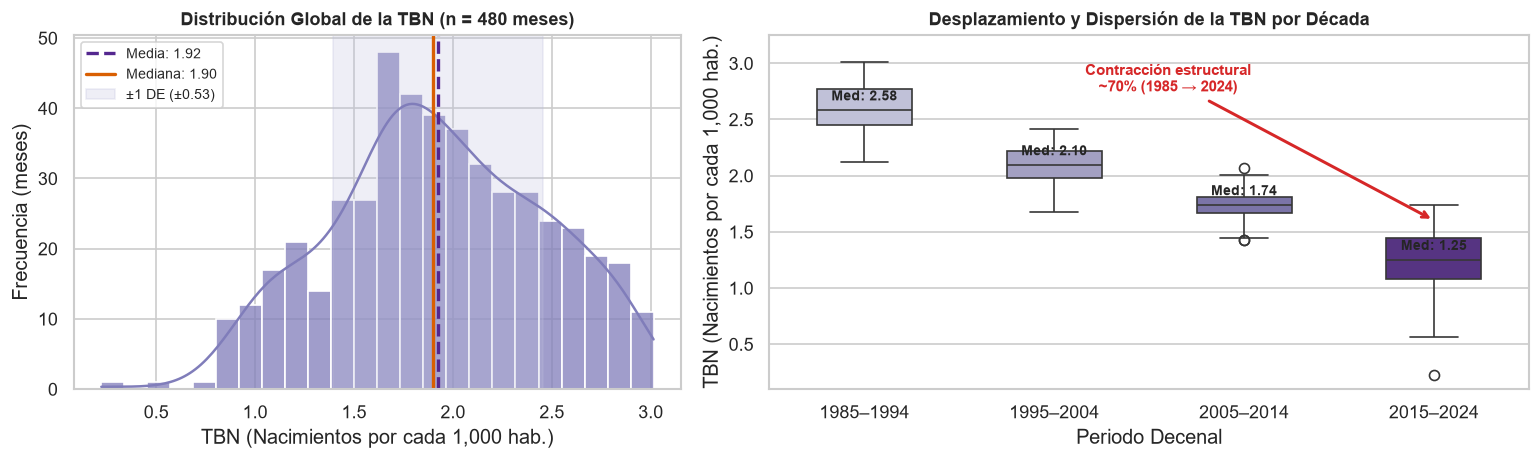

In [22]:
import os
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["figure.dpi"] = 120
sns.set_theme(style="whitegrid")
os.makedirs("graficas_eda", exist_ok=True)

if "con" not in locals():
    con = duckdb.connect("inegi_analytics.db")

df_serie = con.execute("SELECT * FROM vw_serie_nacimientos_mensual").df()
col_anio = next(c for c in df_serie.columns if "anio" in c.lower() or "ano" in c.lower() or "year" in c.lower())
col_mes = next(c for c in df_serie.columns if "mes" in c.lower() or "month" in c.lower())
col_tbn = next(c for c in df_serie.columns if "tbn" in c.lower() or "tasa" in c.lower())

df_serie = df_serie.sort_values([col_anio, col_mes]).reset_index(drop=True)

# Estadísticos globales
media_g = df_serie[col_tbn].mean()
mediana_g = df_serie[col_tbn].median()
de_g = df_serie[col_tbn].std()
iqr_g = np.percentile(df_serie[col_tbn], 75) - np.percentile(df_serie[col_tbn], 25)

# Clasificación por décadas
df_serie["Decada"] = pd.cut(
    df_serie[col_anio],
    bins=[1984, 1994, 2004, 2014, 2024],
    labels=["1985–1994", "1995–2004", "2005–2014", "2015–2024"]
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.0), gridspec_kw={"width_ratios": [1, 1.25]})

# Panel A: Distribución global (Histograma + KDE + Tendencia central)
sns.histplot(df_serie[col_tbn], bins=24, kde=True, color="#807dba", edgecolor="white", alpha=0.75, ax=axes[0])
axes[0].axvline(media_g, color="#54278f", linestyle="--", linewidth=2, label=f"Media: {media_g:.2f}")
axes[0].axvline(mediana_g, color="#d95f02", linestyle="-", linewidth=2, label=f"Mediana: {mediana_g:.2f}")
axes[0].axvspan(media_g - de_g, media_g + de_g, color="#bcbddc", alpha=0.25, label=f"±1 DE (±{de_g:.2f})")

axes[0].set_title("Distribución Global de la TBN (n = 480 meses)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("TBN (Nacimientos por cada 1,000 hab.)")
axes[0].set_ylabel("Frecuencia (meses)")
axes[0].legend(loc="upper left", fontsize=8.5, frameon=True)

# Panel B: Contracción estructural por década
paleta_morada = ["#bcbddc", "#9e9ac8", "#756bb1", "#54278f"]
sns.boxplot(data=df_serie, x="Decada", y=col_tbn, palette=paleta_morada, width=0.5, ax=axes[1])

medianas_dec = df_serie.groupby("Decada", observed=False)[col_tbn].median()
for idx, val in enumerate(medianas_dec):
    axes[1].text(idx, val + 0.06, f"Med: {val:.2f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#252525")

# Flecha de contracción entre primera y última década
axes[1].annotate(
    "Contracción estructural\n~70% (1985 → 2024)",
    xy=(3, medianas_dec.iloc[-1] + 0.35),
    xytext=(1.6, 2.75),
    arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.8),
    fontsize=9, fontweight="bold", color="#d62728", ha="center"
)

axes[1].set_title("Desplazamiento y Dispersión de la TBN por Década", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Periodo Decenal")
axes[1].set_ylabel("TBN (Nacimientos por cada 1,000 hab.)")
axes[1].set_ylim(0.1, 3.25)

plt.tight_layout()
plt.savefig("graficas_eda/eda_0a_descriptiva_decadas.png", dpi=300, bbox_inches="tight")
plt.show()

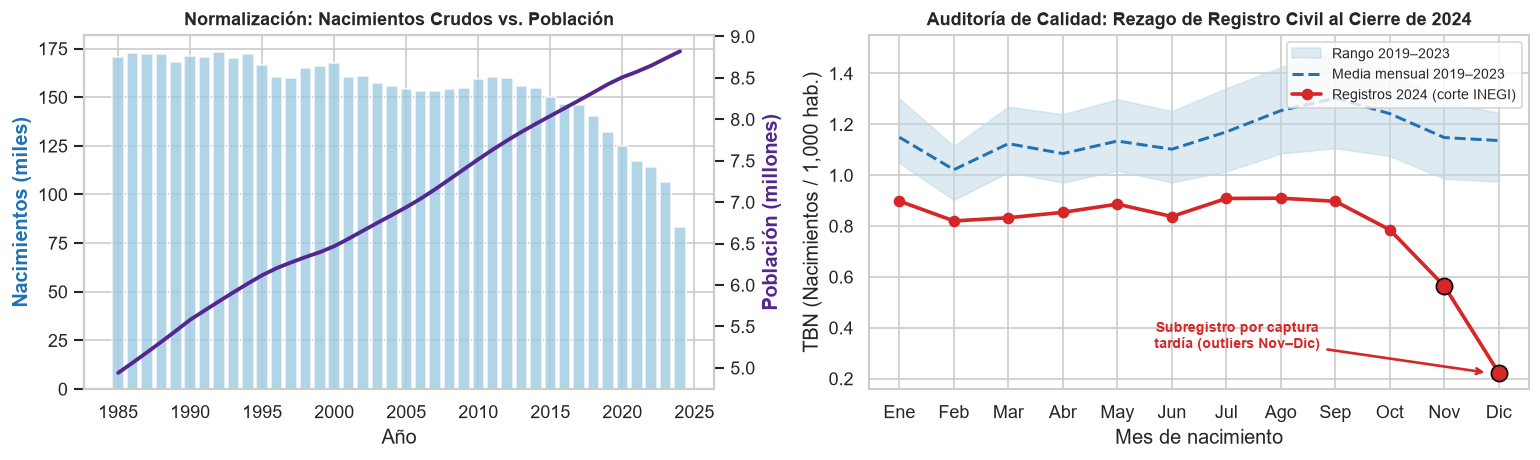

In [23]:
# Detectar columnas de nacimientos crudos y población si están en la vista
col_nac = next((c for c in df_serie.columns if "nac" in c.lower() or "total" in c.lower() or "conteo" in c.lower()), None)
col_pob = next((c for c in df_serie.columns if "pob" in c.lower()), None)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.0), gridspec_kw={"width_ratios": [1.1, 1.15]})

# Panel A: Justificación de la normalización poblacional
if col_nac and col_pob:
    df_anual = df_serie.groupby(col_anio).agg(nacimientos=(col_nac, "sum"), poblacion=(col_pob, "mean")).reset_index()
    ax_pob = axes[0].twinx()
    axes[0].bar(df_anual[col_anio], df_anual["nacimientos"] / 1000, color="#9ecae1", alpha=0.8, label="Nacimientos anuales (miles)")
    ax_pob.plot(df_anual[col_anio], df_anual["poblacion"] / 1e6, color="#54278f", linewidth=2.3, label="Población Jalisco (millones)")
    axes[0].set_ylabel("Nacimientos (miles)", color="#2171b5", fontweight="bold")
    ax_pob.set_ylabel("Población (millones)", color="#54278f", fontweight="bold")
    axes[0].set_title("Normalización: Nacimientos Crudos vs. Población", fontsize=11, fontweight="bold")
    axes[0].set_xlabel("Año")
    ax_pob.grid(False)
else:
    # Alternativa si la vista solo contiene la tasa ya calculada: muestra estabilidad vs TBN anual
    df_anual = df_serie.groupby(col_anio)[col_tbn].agg(["mean", "min", "max"]).reset_index()
    axes[0].fill_between(df_anual[col_anio], df_anual["min"], df_anual["max"], color="#bcbddc", alpha=0.45, label="Rango intraanual (mín–máx)")
    axes[0].plot(df_anual[col_anio], df_anual["mean"], color="#54278f", linewidth=2.2, label="Promedio anual TBN")
    axes[0].set_title("Consistencia Histórica de la Serie Normalizada (TBN)", fontsize=11, fontweight="bold")
    axes[0].set_xlabel("Año")
    axes[0].set_ylabel("TBN (Nacimientos / 1,000 hab.)")
    axes[0].legend(fontsize=8.5)

# Panel B: Auditoría de rezago de registro civil en 2024 (explica los outliers de Nov y Dic)
meses_es = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
ref_19_23 = df_serie[df_serie[col_anio].between(2019, 2023)].groupby(col_mes)[col_tbn].agg(["mean", "min", "max"])
serie_2024 = df_serie[df_serie[col_anio] == 2024].set_index(col_mes)[col_tbn]

axes[1].fill_between(range(1, 13), ref_19_23["min"], ref_19_23["max"], color="#bdd7e7", alpha=0.5, label="Rango 2019–2023")
axes[1].plot(range(1, 13), ref_19_23["mean"], color="#2171b5", linestyle="--", linewidth=1.8, label="Media mensual 2019–2023")
axes[1].plot(serie_2024.index, serie_2024.values, color="#d62728", marker="o", linewidth=2.2, label="Registros 2024 (corte INEGI)")

# Resaltar los dos outliers de noviembre y diciembre
for m_out in [11, 12]:
    if m_out in serie_2024.index:
        axes[1].scatter(m_out, serie_2024.loc[m_out], color="#d62728", s=95, zorder=5, edgecolor="black")

axes[1].annotate(
    "Subregistro por captura\ntardía (outliers Nov–Dic)",
    xy=(11.8, serie_2024.loc[12] if 12 in serie_2024.index else 0.3),
    xytext=(7.2, 0.32),
    arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.6),
    fontsize=8.5, fontweight="bold", color="#d62728", ha="center"
)

axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(meses_es)
axes[1].set_title("Auditoría de Calidad: Rezago de Registro Civil al Cierre de 2024", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Mes de nacimiento")
axes[1].set_ylabel("TBN (Nacimientos / 1,000 hab.)")
axes[1].legend(loc="upper right", fontsize=8.5, frameon=True)

plt.tight_layout()
plt.savefig("graficas_eda/eda_0b_auditoria_calidad.png", dpi=300, bbox_inches="tight")
plt.show()

Comparación de datos crudos y base de datos consolidada

In [24]:
from pathlib import Path

archivos_crudos = [p for p in Path("crudos_inegi").rglob("*") if p.is_file()]
print(f"Total en crudos_inegi: {len(archivos_crudos)}")
for a in archivos_crudos[:15]:
    print(" ", a)

Total en crudos_inegi: 24
  crudos_inegi\natalidad_base_datos_2010_dbf\descripcion_bd_nacimientos_2010.pdf
  crudos_inegi\natalidad_base_datos_2010_dbf\ENTMUN.dbf
  crudos_inegi\natalidad_base_datos_2010_dbf\NACIM10.dbf
  crudos_inegi\natalidad_base_datos_2011_dbf\descripcion_bd_nacimientos_2011.pdf
  crudos_inegi\natalidad_base_datos_2011_dbf\ENTMUN.DBF
  crudos_inegi\natalidad_base_datos_2011_dbf\NACIM11.dbf
  crudos_inegi\natalidad_base_datos_2012_dbf\descripcion_bd_nacimientos_2012.pdf
  crudos_inegi\natalidad_base_datos_2012_dbf\ENTMUN.dbf
  crudos_inegi\natalidad_base_datos_2012_dbf\NACIM12.dbf
  crudos_inegi\natalidad_base_datos_2013_dbf\CATEMLNA13.dbf
  crudos_inegi\natalidad_base_datos_2013_dbf\descripcion_bd_nacimientos_2013.pdf
  crudos_inegi\natalidad_base_datos_2013_dbf\NACIM13.dbf
  crudos_inegi\natalidad_base_datos_2014_dbf\CATEMLN14.dbf
  crudos_inegi\natalidad_base_datos_2014_dbf\descripcion_bd_nacimientos_2014.pdf
  crudos_inegi\natalidad_base_datos_2014_dbf\NACIM14.d

In [25]:
from pathlib import Path
import pandas as pd
from dbfread import DBF

carpeta_crudos = Path("crudos_inegi")
carpeta_salida = Path("crudos_parquet")
carpeta_salida.mkdir(exist_ok=True)

archivos_nacim = sorted(
    p for p in carpeta_crudos.rglob("*")
    if p.is_file() and p.stem.upper().startswith("NACIM") and p.suffix.lower() in {".dbf", ".csv"}
)

print(f"Archivos de nacimientos encontrados: {len(archivos_nacim)}")

for ruta in archivos_nacim:
    salida = carpeta_salida / f"{ruta.stem.lower()}.parquet"
    if salida.exists():
        print(f"Ya existe: {salida.name}")
        continue

    print(f"Convirtiendo {ruta.name}...")
    if ruta.suffix.lower() == ".dbf":
        tabla = DBF(ruta, encoding="latin1", char_decode_errors="ignore")
        df = pd.DataFrame(iter(tabla))
    else:
        df = pd.read_csv(ruta, encoding="latin1", low_memory=False)

    df.columns = [c.upper().strip() for c in df.columns]
    for col in ["ENT_RESID", "MUN_RESID", "ENT_REGIS", "ENT_OCURR"]:
        if col in df.columns:
            df[col] = df[col].astype(str).str.strip().str.zfill(2 if "ENT" in col else 3)

    df.to_parquet(salida, index=False)
    print(f" -> Guardado {salida.name} ({len(df):,} filas)")

print("Conversión completada.")

Archivos de nacimientos encontrados: 8
Ya existe: nacim10.parquet
Ya existe: nacim11.parquet
Ya existe: nacim12.parquet
Ya existe: nacim13.parquet
Ya existe: nacim14.parquet
Ya existe: nacim15.parquet
Ya existe: nacim16.parquet
Ya existe: nacim17.parquet
Conversión completada.


In [26]:
comparacion = con.execute("""
    WITH crudos AS (
        SELECT 
            CAST(ANO_REG AS INTEGER) AS anio,
            COUNT(*) AS filas_crudas,
            SUM(CAST(EDAD_MADN AS BIGINT)) AS checksum_crudo
        FROM read_parquet('crudos_parquet/*.parquet', union_by_name = true)
        WHERE CAST(ENT_RESID AS INTEGER) = 14
        GROUP BY 1
    ),
    consolidada AS (
        SELECT 
            CAST(ANO_REG AS INTEGER) AS anio,
            COUNT(*) AS filas_consolidadas,
            SUM(CAST(EDAD_MADN AS BIGINT)) AS checksum_consolidado
        FROM read_parquet('natalidad_optimizada.parquet')
        WHERE CAST(ENT_RESID AS INTEGER) = 14
        GROUP BY 1
    )
    SELECT 
        c.anio AS anio_registro,
        c.filas_crudas,
        b.filas_consolidadas,
        (b.filas_consolidadas - c.filas_crudas) AS dif_filas,
        (b.checksum_consolidado - c.checksum_crudo) AS dif_checksum
    FROM crudos c
    LEFT JOIN consolidada b ON c.anio = b.anio
    ORDER BY anio_registro
""").df()

print(comparacion.to_string(index=False))

 anio_registro  filas_crudas  filas_consolidadas  dif_filas  dif_checksum
          2010        161543              161543          0           0.0
          2011        163123              163123          0           0.0
          2012        161217              161217          0           0.0
          2013        159748              159748          0           0.0
          2014        158592              158592          0           0.0
          2015        151578              151578          0          64.0
          2016        148377              148377          0           0.0
          2017        151950              151950          0           0.0


In [27]:
import duckdb

con = duckdb.connect("inegi_analytics.db")
print(con.execute("DESCRIBE SELECT * FROM 'natalidad_optimizada.parquet'").df()[["column_name", "column_type"]].to_string(index=False))

column_name column_type
    id_insp      DOUBLE
  cve_regis     VARCHAR
  ent_regis     VARCHAR
  mun_regis     VARCHAR
  loc_regis      BIGINT
 tloc_regis      BIGINT
  cve_resid      BIGINT
  ent_resid      BIGINT
  mun_resid     VARCHAR
  loc_resid      BIGINT
 tloc_resid      BIGINT
  cve_ocurr     VARCHAR
  ent_ocurr     VARCHAR
  mun_ocurr     VARCHAR
  loc_ocurr      BIGINT
 tloc_ocurr      BIGINT
       sexo      BIGINT
   edad_reg      BIGINT
  edad_madn      BIGINT
  edad_padn      BIGINT
   date_nac     VARCHAR
    dia_nac      BIGINT
    mes_nac      BIGINT
    ano_nac      BIGINT
   date_reg     VARCHAR
    dia_reg     VARCHAR
    mes_reg      BIGINT
    ano_reg      BIGINT
  edad_madr      BIGINT
  edad_padr      BIGINT
   tipo_nac      BIGINT
 orden_part      BIGINT
 lugar_part      BIGINT
  q_atendio      BIGINT
 hijos_vivo      BIGINT
 hijos_sobr      BIGINT
 edociv_mad      BIGINT
  escol_mad      BIGINT
  escol_pad      BIGINT
    act_mad      BIGINT
    act_pad     

In [39]:
con.execute("""
CREATE OR REPLACE TABLE silver_jalisco AS
WITH base_limpia AS (
    SELECT
        TRY_CAST(ano_reg AS INTEGER) AS anio_registro,
        TRY_CAST(ano_nac AS INTEGER) AS anio_nac,
        TRY_CAST(mes_nac AS INTEGER) AS mes_nac,
        LPAD(TRIM(CAST(mun_resid AS VARCHAR)), 3, '0') AS cve_municipio,
        
        -- Métricas numéricas (99 = No especificado en INEGI)
        NULLIF(TRY_CAST(edad_madn AS INTEGER), 99) AS edad_madre,
        NULLIF(TRY_CAST(edad_padn AS INTEGER), 99) AS edad_padre,
        NULLIF(TRY_CAST(orden_part AS INTEGER), 99) AS orden_parto,
        NULLIF(TRY_CAST(hijos_vivo AS INTEGER), 99) AS hijos_vivos,
        
        -- Claves categóricas homologadas (0 = No especificado)
        COALESCE(NULLIF(TRY_CAST(sexo AS INTEGER), 9), 0) AS cod_sexo,
        COALESCE(NULLIF(TRY_CAST(escol_mad AS INTEGER), 99), 0) AS cod_escolaridad,
        COALESCE(NULLIF(TRY_CAST(edociv_mad AS INTEGER), 9), 0) AS cod_edociv,
        COALESCE(NULLIF(TRY_CAST(act_mad AS INTEGER), 9), 0) AS cod_actividad,
        COALESCE(NULLIF(TRY_CAST(tipo_nac AS INTEGER), 9), 0) AS cod_tipo_parto,
        COALESCE(NULLIF(TRY_CAST(lugar_part AS INTEGER), 9), 0) AS cod_lugar_parto,
        COALESCE(NULLIF(TRY_CAST(q_atendio AS INTEGER), 9), 0) AS cod_atendio
    FROM read_parquet('natalidad_optimizada.parquet')
    WHERE TRY_CAST(ent_resid AS INTEGER) = 14
      AND TRY_CAST(ano_nac AS INTEGER) BETWEEN 1985 AND 2024
      AND TRY_CAST(mes_nac AS INTEGER) BETWEEN 1 AND 12
)
SELECT
    *,
    CASE 
        WHEN edad_madre IS NULL THEN 'No especificado'
        WHEN edad_madre < 15 THEN 'Menor de 15'
        WHEN edad_madre BETWEEN 15 AND 19 THEN '15 a 19 años'
        WHEN edad_madre BETWEEN 20 AND 24 THEN '20 a 24 años'
        WHEN edad_madre BETWEEN 25 AND 29 THEN '25 a 29 años'
        WHEN edad_madre BETWEEN 30 AND 34 THEN '30 a 34 años'
        WHEN edad_madre BETWEEN 35 AND 39 THEN '35 a 39 años'
        ELSE '40 años o más'
    END AS grupo_edad_madre
FROM base_limpia;
""")

print("Registros en Capa Plata (Jalisco 1985-2024):", con.execute("SELECT COUNT(*) FROM silver_jalisco").fetchone()[0])

Registros en Capa Plata (Jalisco 1985-2024): 5830641


In [40]:
columnas = con.execute("DESCRIBE SELECT * FROM 'natalidad_optimizada.parquet'").df()
print(list(columnas["column_name"]))

['id_insp', 'cve_regis', 'ent_regis', 'mun_regis', 'loc_regis', 'tloc_regis', 'cve_resid', 'ent_resid', 'mun_resid', 'loc_resid', 'tloc_resid', 'cve_ocurr', 'ent_ocurr', 'mun_ocurr', 'loc_ocurr', 'tloc_ocurr', 'sexo', 'edad_reg', 'edad_madn', 'edad_padn', 'date_nac', 'dia_nac', 'mes_nac', 'ano_nac', 'date_reg', 'dia_reg', 'mes_reg', 'ano_reg', 'edad_madr', 'edad_padr', 'tipo_nac', 'orden_part', 'lugar_part', 'q_atendio', 'hijos_vivo', 'hijos_sobr', 'edociv_mad', 'escol_mad', 'escol_pad', 'act_mad', 'act_pad', 'pos_mad', 'pos_pad', 'sitlab_mad', 'sitlab_pad', 'fue_prese', 'hora_nac', 'minuto_nac', 'comparecio', 'dis_re_oax', 'anio_base', 'q_ate_insp']


1. Capa Plata (silver_jalisco)

In [41]:
con.execute("""
CREATE OR REPLACE TABLE silver_jalisco AS
WITH base_limpia AS (
    SELECT
        TRY_CAST(ano_reg AS INTEGER) AS anio_registro,
        TRY_CAST(ano_nac AS INTEGER) AS anio_nac,
        TRY_CAST(mes_nac AS INTEGER) AS mes_nac,
        LPAD(TRIM(CAST(mun_resid AS VARCHAR)), 3, '0') AS cve_municipio,
        
        -- Métricas numéricas (99 = No especificado en INEGI)
        NULLIF(TRY_CAST(edad_madn AS INTEGER), 99) AS edad_madre,
        NULLIF(TRY_CAST(edad_padn AS INTEGER), 99) AS edad_padre,
        NULLIF(TRY_CAST(orden_part AS INTEGER), 99) AS orden_parto,
        NULLIF(TRY_CAST(hijos_vivo AS INTEGER), 99) AS hijos_vivos,
        
        -- Claves categóricas homologadas (0 = No especificado)
        COALESCE(NULLIF(TRY_CAST(sexo AS INTEGER), 9), 0) AS cod_sexo,
        COALESCE(NULLIF(TRY_CAST(escol_mad AS INTEGER), 99), 0) AS cod_escolaridad,
        COALESCE(NULLIF(TRY_CAST(edociv_mad AS INTEGER), 9), 0) AS cod_edociv,
        COALESCE(NULLIF(TRY_CAST(act_mad AS INTEGER), 9), 0) AS cod_actividad,
        COALESCE(NULLIF(TRY_CAST(tipo_nac AS INTEGER), 9), 0) AS cod_tipo_parto,
        COALESCE(NULLIF(TRY_CAST(lugar_part AS INTEGER), 9), 0) AS cod_lugar_parto,
        COALESCE(NULLIF(TRY_CAST(q_atendio AS INTEGER), 9), 0) AS cod_atendio
    FROM read_parquet('natalidad_optimizada.parquet')
    WHERE TRY_CAST(ent_resid AS INTEGER) = 14
      AND TRY_CAST(ano_nac AS INTEGER) BETWEEN 1985 AND 2024
      AND TRY_CAST(mes_nac AS INTEGER) BETWEEN 1 AND 12
)
SELECT
    *,
    CASE 
        WHEN edad_madre IS NULL THEN 'No especificado'
        WHEN edad_madre < 15 THEN 'Menor de 15'
        WHEN edad_madre BETWEEN 15 AND 19 THEN '15 a 19 años'
        WHEN edad_madre BETWEEN 20 AND 24 THEN '20 a 24 años'
        WHEN edad_madre BETWEEN 25 AND 29 THEN '25 a 29 años'
        WHEN edad_madre BETWEEN 30 AND 34 THEN '30 a 34 años'
        WHEN edad_madre BETWEEN 35 AND 39 THEN '35 a 39 años'
        ELSE '40 años o más'
    END AS grupo_edad_madre
FROM base_limpia;
""")

print("Registros en Capa Plata (Jalisco 1985-2024):", con.execute("SELECT COUNT(*) FROM silver_jalisco").fetchone()[0])

Registros en Capa Plata (Jalisco 1985-2024): 5830641


In [42]:
# 1. Dimensión Tiempo (480 meses: 1985-01 a 2024-12)
con.execute("""
CREATE OR REPLACE TABLE dim_tiempo AS
SELECT
    (anio * 100 + mes) AS id_tiempo,
    anio,
    mes,
    MAKE_DATE(anio, mes, 1) AS fecha,
    ((mes - 1) // 3) + 1 AS trimestre,
    (anio // 10) * 10 AS decada,
    CASE WHEN anio IN (2020, 2021) THEN TRUE ELSE FALSE END AS es_periodo_pandemia
FROM range(1985, 2025) t1(anio)
CROSS JOIN range(1, 13) t2(mes);
""")

# 2. Dimensión Geográfica (AMG vs. Interior de Jalisco)
con.execute("""
CREATE OR REPLACE TABLE dim_municipio AS
SELECT DISTINCT
    cve_municipio AS id_municipio,
    CASE 
        WHEN cve_municipio IN ('039','120','098','101','097','070','044','051','124') 
            THEN 'Área Metropolitana de Guadalajara'
        ELSE 'Interior del Estado'
    END AS zona_geografica
FROM silver_jalisco
WHERE cve_municipio IS NOT NULL AND cve_municipio <> '999';
""")

# 3. Dimensión Perfil Sociodemográfico de la Madre
con.execute("""
CREATE OR REPLACE TABLE dim_perfil_madre AS
WITH combinaciones AS (
    SELECT DISTINCT
        grupo_edad_madre,
        cod_escolaridad,
        cod_edociv,
        CASE cod_edociv
            WHEN 1 THEN 'Soltera'
            WHEN 2 THEN 'Casada'
            WHEN 3 THEN 'Unión libre'
            WHEN 4 THEN 'Separada / Divorciada'
            WHEN 5 THEN 'Viuda'
            ELSE 'No especificado'
        END AS estado_civil,
        cod_actividad,
        CASE cod_actividad
            WHEN 1 THEN 'Trabaja'
            WHEN 2 THEN 'No trabaja'
            ELSE 'No especificado'
        END AS condicion_actividad
    FROM silver_jalisco
)
SELECT 
    ROW_NUMBER() OVER (ORDER BY grupo_edad_madre, cod_escolaridad, cod_edociv, cod_actividad) AS id_perfil_madre,
    *
FROM combinaciones;
""")

# 4. Dimensión Condición del Parto y Atención Médica
con.execute("""
CREATE OR REPLACE TABLE dim_condicion_parto AS
WITH combinaciones AS (
    SELECT DISTINCT
        cod_sexo,
        CASE cod_sexo
            WHEN 1 THEN 'Hombre'
            WHEN 2 THEN 'Mujer'
            ELSE 'No especificado'
        END AS sexo,
        cod_tipo_parto,
        CASE cod_tipo_parto
            WHEN 1 THEN 'Simple'
            WHEN 2 THEN 'Doble (Gemelar)'
            WHEN 3 THEN 'Triple o más'
            ELSE 'No especificado'
        END AS tipo_parto,
        cod_lugar_parto,
        CASE cod_lugar_parto
            WHEN 1 THEN 'Hospital / Clínica'
            WHEN 2 THEN 'Domicilio'
            ELSE 'Otro / No especificado'
        END AS lugar_parto,
        cod_atendio,
        CASE cod_atendio
            WHEN 1 THEN 'Médico'
            WHEN 2 THEN 'Enfermera / Partera'
            ELSE 'Otro / No especificado'
        END AS persona_atendio
    FROM silver_jalisco
)
SELECT 
    ROW_NUMBER() OVER (ORDER BY cod_sexo, cod_tipo_parto, cod_lugar_parto, cod_atendio) AS id_condicion_parto,
    *
FROM combinaciones;
""")

In [43]:
con.execute("""
CREATE OR REPLACE TABLE fact_nacimientos AS
SELECT
    (s.anio_nac * 100 + s.mes_nac) AS id_tiempo,
    COALESCE(m.id_municipio, '999') AS id_municipio,
    pm.id_perfil_madre,
    cp.id_condicion_parto,
    s.anio_registro,
    (s.anio_registro - s.anio_nac) AS rezago_registro_anios,
    s.edad_madre,
    s.edad_padre,
    s.orden_parto,
    s.hijos_vivos
FROM silver_jalisco s
LEFT JOIN dim_municipio m 
    ON s.cve_municipio = m.id_municipio
LEFT JOIN dim_perfil_madre pm 
    ON s.grupo_edad_madre = pm.grupo_edad_madre
    AND s.cod_escolaridad = pm.cod_escolaridad
    AND s.cod_edociv = pm.cod_edociv
    AND s.cod_actividad = pm.cod_actividad
LEFT JOIN dim_condicion_parto cp 
    ON s.cod_sexo = cp.cod_sexo 
    AND s.cod_tipo_parto = cp.cod_tipo_parto
    AND s.cod_lugar_parto = cp.cod_lugar_parto
    AND s.cod_atendio = cp.cod_atendio;
""")

print("Filas en fact_nacimientos:", con.execute("SELECT COUNT(*) FROM fact_nacimientos").fetchone()[0])

Filas en fact_nacimientos: 5830641


In [44]:
# Vista 1: Serie de tiempo mensual (480 filas) para SARIMA y Regresión Bayesiana
con.execute("""
CREATE OR REPLACE VIEW vw_serie_nacimientos_mensual AS
SELECT
    t.id_tiempo,
    t.fecha,
    t.anio,
    t.mes,
    t.trimestre,
    t.decada,
    t.es_periodo_pandemia,
    COUNT(f.id_tiempo) AS nacimientos_ocurridos,
    p.poblacion_total,
    ROUND((COUNT(f.id_tiempo) * 1000.0) / p.poblacion_total, 4) AS tbn_mensual
FROM dim_tiempo t
LEFT JOIN fact_nacimientos f ON t.id_tiempo = f.id_tiempo
LEFT JOIN dim_poblacion_jalisco p ON t.anio = p.anio
GROUP BY 
    t.id_tiempo,
    t.fecha,
    t.anio,
    t.mes,
    t.trimestre,
    t.decada,
    t.es_periodo_pandemia,
    p.poblacion_total
ORDER BY t.id_tiempo;
""")

# Vista 2: Cohorte limpia para ANOVA / Kruskal-Wallis en Probabilidad y Estadística
con.execute("""
CREATE OR REPLACE VIEW vw_anova_edad_materna AS
SELECT
    t.anio,
    t.decada,
    m.zona_geografica,
    pm.estado_civil,
    pm.condicion_actividad,
    f.edad_madre,
    f.orden_parto,
    f.hijos_vivos
FROM fact_nacimientos f
JOIN dim_tiempo t ON f.id_tiempo = t.id_tiempo
JOIN dim_municipio m ON f.id_municipio = m.id_municipio
JOIN dim_perfil_madre pm ON f.id_perfil_madre = pm.id_perfil_madre
WHERE f.edad_madre IS NOT NULL 
  AND f.edad_madre BETWEEN 10 AND 55;
""")

print("Vistas analíticas creadas exitosamente.")

Vistas analíticas creadas exitosamente.


In [45]:
import os
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Estilo visual limpio para el cartel académico
plt.rcParams["figure.dpi"] = 120
sns.set_theme(style="whitegrid")
os.makedirs("graficas_eda", exist_ok=True)

# Reutilizar conexión abierta o conectar a la base local
if "con" not in locals():
    con = duckdb.connect("inegi_analytics.db")

df_serie = con.execute("SELECT * FROM vw_serie_nacimientos_mensual").df()
print("Columnas detectadas:", df_serie.columns.tolist())

# Detección automática de columnas de año, mes y TBN
col_anio = next(c for c in df_serie.columns if "anio" in c.lower() or "ano" in c.lower() or "year" in c.lower())
col_mes = next(c for c in df_serie.columns if "mes" in c.lower() or "month" in c.lower())
col_tbn = next(c for c in df_serie.columns if "tbn" in c.lower() or "tasa" in c.lower())

# Ordenar cronológicamente y crear índice de fecha mensual
df_serie = df_serie.sort_values([col_anio, col_mes]).reset_index(drop=True)
df_serie["fecha"] = pd.to_datetime(
    dict(year=df_serie[col_anio], month=df_serie[col_mes], day=1)
)
serie_tbn = df_serie.set_index("fecha")[col_tbn].asfreq("MS")

print(f"Observaciones cargadas: {len(serie_tbn)} meses ({serie_tbn.index.min():%Y-%m} a {serie_tbn.index.max():%Y-%m})")

Columnas detectadas: ['id_tiempo', 'fecha', 'anio', 'mes', 'trimestre', 'decada', 'es_periodo_pandemia', 'nacimientos_ocurridos', 'poblacion_total', 'tbn_mensual']
Observaciones cargadas: 480 meses (1985-01 a 2024-12)


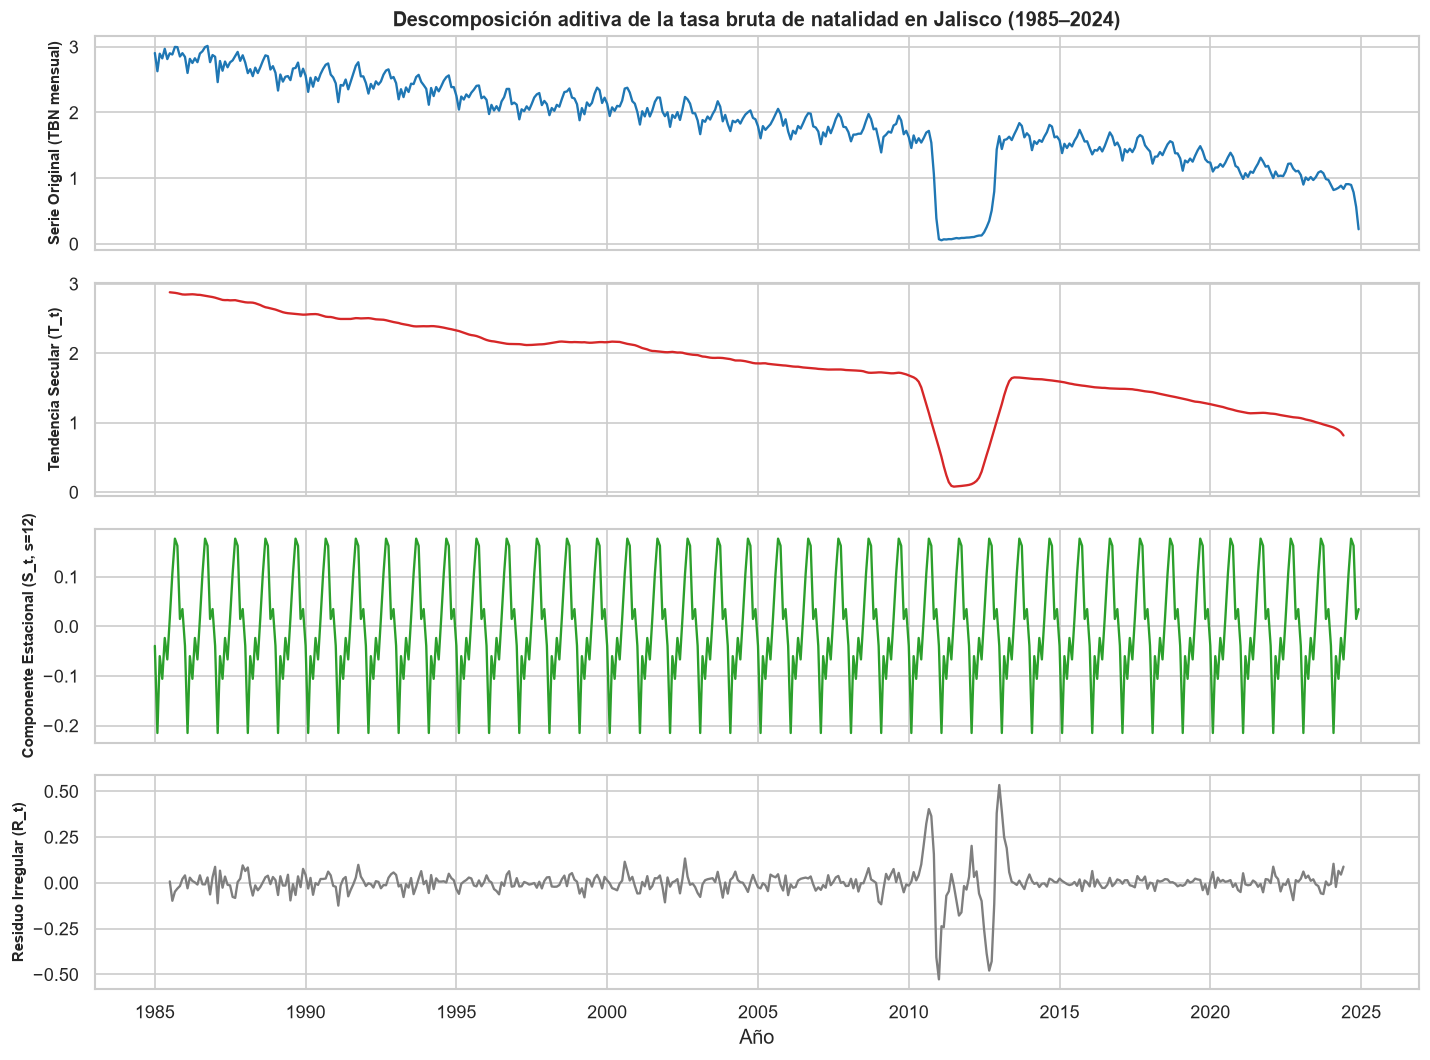

Tendencia inicial (1985): 2.878 | Tendencia final (2024): 0.816
Variación estructural acumulada de la tendencia: -71.65%


In [46]:
descomposicion = seasonal_decompose(serie_tbn.dropna(), model="additive", period=12)

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
componentes = [
    (descomposicion.observed, "Serie Original (TBN mensual)", "#1f77b4"),
    (descomposicion.trend, "Tendencia Secular (T_t)", "#d62728"),
    (descomposicion.seasonal, "Componente Estacional (S_t, s=12)", "#2ca02c"),
    (descomposicion.resid, "Residuo Irregular (R_t)", "#7f7f7f"),
]

for ax, (datos, titulo, color) in zip(axes, componentes):
    ax.plot(datos.index, datos.values, color=color, linewidth=1.4)
    ax.set_ylabel(titulo, fontsize=9, fontweight="bold")

axes[0].set_title("Descomposición aditiva de la tasa bruta de natalidad en Jalisco (1985–2024)", fontsize=12, fontweight="bold")
axes[-1].set_xlabel("Año")
plt.tight_layout()
plt.savefig("graficas_eda/eda_1_descomposicion.png", dpi=300, bbox_inches="tight")
plt.show()

# Métrica cuantitativa de contracción de la tendencia
tendencia_valida = descomposicion.trend.dropna()
caida_pct = ((tendencia_valida.iloc[-1] - tendencia_valida.iloc[0]) / tendencia_valida.iloc[0]) * 100
print(f"Tendencia inicial (1985): {tendencia_valida.iloc[0]:.3f} | Tendencia final (2024): {tendencia_valida.iloc[-1]:.3f}")
print(f"Variación estructural acumulada de la tendencia: {caida_pct:.2f}%")

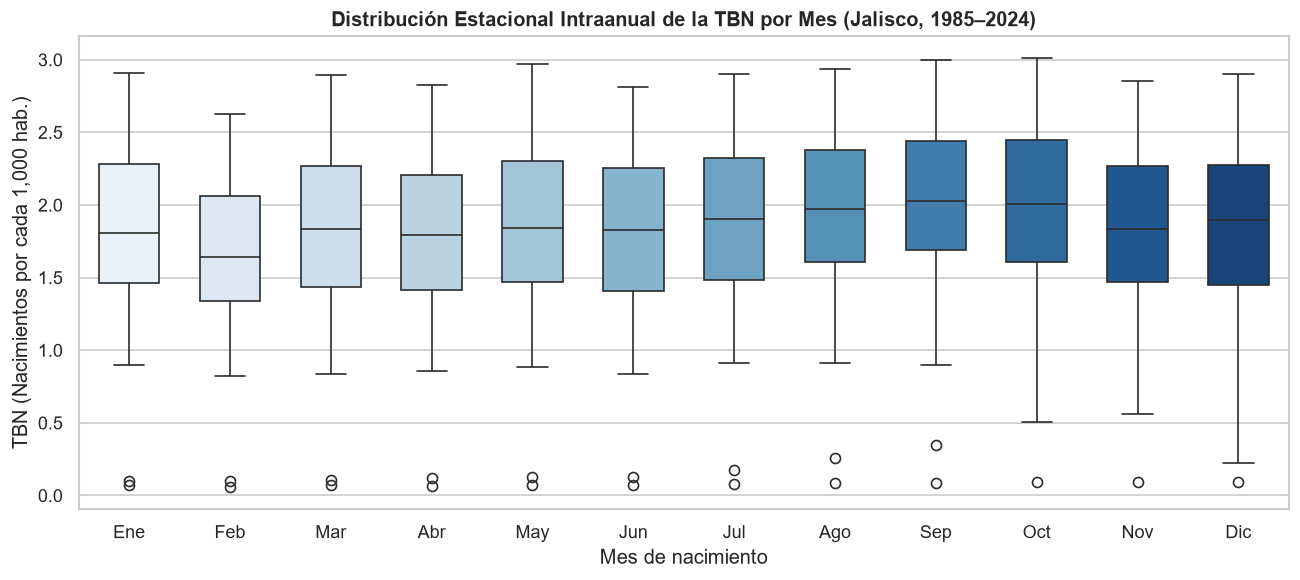


Resumen estadístico por mes (ordenado de mayor a menor mediana):
     Mediana   Media     IQR
Sep   2.0296  2.0023  0.7514
Oct   2.0069  1.9814  0.8400
Ago   1.9702  1.9377  0.7733
Jul   1.8994  1.8537  0.8428
Dic   1.8969  1.8344  0.8310
May   1.8410  1.8246  0.8340
Mar   1.8332  1.7961  0.8329
Nov   1.8312  1.8277  0.7961
Jun   1.8261  1.7733  0.8476
Ene   1.8062  1.8249  0.8200
Abr   1.7932  1.7452  0.7933
Feb   1.6386  1.6426  0.7239


In [8]:
meses_es = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

plt.figure(figsize=(11, 5))
sns.boxplot(
    data=df_serie,
    x=col_mes,
    y=col_tbn,
    palette="Blues",
    width=0.6
)
plt.xticks(ticks=range(12), labels=meses_es)
plt.title("Distribución Estacional Intraanual de la TBN por Mes (Jalisco, 1985–2024)", fontsize=12, fontweight="bold")
plt.xlabel("Mes de nacimiento")
plt.ylabel("TBN (Nacimientos por cada 1,000 hab.)")
plt.tight_layout()
plt.savefig("graficas_eda/eda_2_boxplots_mensuales.png", dpi=300, bbox_inches="tight")
plt.show()

# Resumen numérico por mes para reportar picos y valles
resumen_mensual = df_serie.groupby(col_mes)[col_tbn].agg(Mediana="median", Media="mean", IQR=lambda x: np.percentile(x, 75) - np.percentile(x, 25))
resumen_mensual.index = meses_es
print("\nResumen estadístico por mes (ordenado de mayor a menor mediana):")
print(resumen_mensual.sort_values("Mediana", ascending=False).round(4))

In [9]:
def evaluar_adf(serie, nombre):
    s = serie.dropna()
    stat, p_val, rezagos, n_obs, criticos, _ = adfuller(s, autolag="AIC")
    return {
        "Transformación": nombre,
        "Estadístico ADF": round(stat, 4),
        "p-valor": f"{p_val:.4e}",
        "Valor Crítico (5%)": round(criticos["5%"], 4),
        "Rezagos": rezagos,
        "¿Estacionaria? (α=0.05)": "Sí (Rechaza H0)" if p_val < 0.05 else "No (Raíz unitaria)"
    }

serie_d1 = serie_tbn.diff(1)
serie_d1_D1 = serie_tbn.diff(1).diff(12)

tabla_adf = pd.DataFrame([
    evaluar_adf(serie_tbn, "Serie original (d=0, D=0)"),
    evaluar_adf(serie_d1, "1ra diferencia regular (d=1)"),
    evaluar_adf(serie_d1_D1, "Diferencia regular y estacional (d=1, D=1)")
])

print("Resultados de la Prueba de Dickey-Fuller Aumentada (ADF):")
display(tabla_adf)

Resultados de la Prueba de Dickey-Fuller Aumentada (ADF):


,Transformación,Estadístico ADF,p-valor,Valor Crítico (5%),Rezagos,¿Estacionaria? (α=0.05)
0,"Serie original (d=0, D=0)",-1.5255,5.2087e-01,-2.8678,14,No (Raíz unitaria)
1,1ra diferencia regular (d=1),-4.5662,1.4904e-04,-2.8678,13,Sí (Rechaza H0)
2,"Diferencia regular y estacional (d=1, D=1)",-6.1310,8.4028e-08,-2.8679,12,Sí (Rechaza H0)


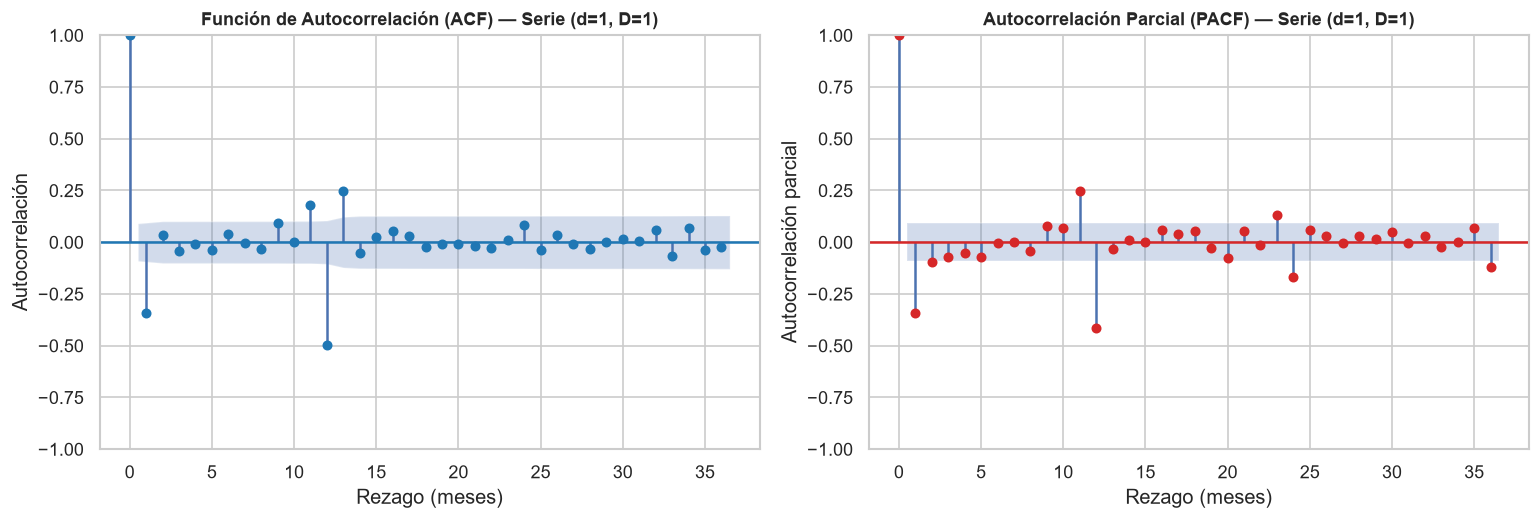

In [10]:
serie_estacionaria = serie_tbn.diff(1).diff(12).dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

plot_acf(serie_estacionaria, lags=36, ax=axes[0], color="#1f77b4")
axes[0].set_title("Función de Autocorrelación (ACF) — Serie (d=1, D=1)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Rezago (meses)")
axes[0].set_ylabel("Autocorrelación")

plot_pacf(serie_estacionaria, lags=36, method="ywm", ax=axes[1], color="#d62728")
axes[1].set_title("Autocorrelación Parcial (PACF) — Serie (d=1, D=1)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Rezago (meses)")
axes[1].set_ylabel("Autocorrelación parcial")

plt.tight_layout()
plt.savefig("graficas_eda/eda_4_acf_pacf.png", dpi=300, bbox_inches="tight")
plt.show()

In [19]:
print(con.execute("""
    SELECT * 
    FROM read_csv_auto(
        'pobproy_quinq1.csv',
        all_varchar = true,
        quote = '"',
        strict_mode = false,
        null_padding = true,
        ignore_errors = true
    )
    WHERE TRY_CAST(CLAVE_ENT AS INTEGER) = 14 
      AND TRY_CAST(ANO AS INTEGER) = 2020
    LIMIT 10
""").df().to_string(index=False))

CLAVE CLAVE_ENT NOM_ENT              NOM_MUN    SEXO  ANO POB_TOTAL POB_00_04 POB_05_09 POB_010_014 POB_015_019 POB_20_24 POB_25_29 POB_30_34 POB_35_39 POB_40_44 POB_45_49 POB_50_54 POB_55_59 POB_60_64 POB_65_69 POB_70_74 POB_75_79 POB_80_84 POB_85_mm      fecha etiqueta_estado
14001        14 Jalisco               Acatic HOMBRES 2020     11642      1203      1133        1204        1139      1007       913       839       739       675       637       512       397       322       276       240       184       116       106 2020-01-01         Jalisco
14001        14 Jalisco               Acatic MUJERES 2020     11987      1149      1148        1164        1078      1005       983       925       833       750       658       517       426       366       307       258       201       126        93 2020-01-01         Jalisco
14002        14 Jalisco    Acatlán de Juárez HOMBRES 2020     13590      1225      1152        1948        1730      1172       988       886       701       640  

In [20]:
con.execute("""
CREATE OR REPLACE TABLE dim_poblacion_jalisco AS
SELECT 
    TRY_CAST(ANO AS INTEGER) AS anio,
    SUM(TRY_CAST(POB_TOTAL AS BIGINT)) AS poblacion_total
FROM read_csv_auto(
    'pobproy_quinq1.csv',
    all_varchar = true,
    quote = '"',
    strict_mode = false,
    null_padding = true,
    ignore_errors = true
)
WHERE TRY_CAST(CLAVE_ENT AS INTEGER) = 14
  AND TRY_CAST(ANO AS INTEGER) BETWEEN 1985 AND 2024
  -- Si en el paso 1 viste una fila de subtotal en SEXO, descomenta la siguiente línea:
  -- AND UPPER(TRIM(SEXO)) NOT IN ('TOTAL', 'AMBOS SEXOS')
GROUP BY 1
ORDER BY 1;
""")

print(con.execute("""
    SELECT * FROM dim_poblacion_jalisco 
    WHERE anio IN (1985, 1990, 2000, 2010, 2020, 2024)
""").df().to_string(index=False))

 anio  poblacion_total
 1990        5579963.0
 2000        6467806.0
 2010        7517154.0
 2020        8507662.0
 2024        8820915.0


In [21]:
import numpy as np

pob_1980 = 4371998
pob_1990 = con.execute("SELECT poblacion_total FROM dim_poblacion_jalisco WHERE anio = 1990").fetchone()[0]
r = (np.log(pob_1990) - np.log(pob_1980)) / (1990 - 1980)

# Limpiar años previos a 1990 para evitar duplicados si se vuelve a correr la celda
con.execute("DELETE FROM dim_poblacion_jalisco WHERE anio < 1990;")

for anio in range(1985, 1990):
    pob_est = int(round(pob_1980 * np.exp(r * (anio - 1980))))
    con.execute("INSERT INTO dim_poblacion_jalisco VALUES (?, ?)", [anio, pob_est])

# Verificar que los 480 meses tengan su Tasa Bruta de Natalidad calculada
print(con.execute("""
    SELECT COUNT(*) AS meses_totales, COUNT(tbn_mensual) AS meses_con_tasa
    FROM vw_serie_nacimientos_mensual
""").df().to_string(index=False))

 meses_totales  meses_con_tasa
           480             480


Bloque 1: Pruebas de hipótesis sobre la edad materna (ANOVA y Kruskal-Wallis)

In [22]:
import duckdb
import pandas as pd
from scipy import stats

con = duckdb.connect("inegi_analytics.db")

# 1. Actualizar la vista con las columnas existentes en dim_perfil_madre y fact_nacimientos
con.execute("""
CREATE OR REPLACE VIEW vw_anova_edad_materna AS
SELECT
    t.anio,
    t.decada,
    m.zona_geografica,
    pm.grupo_edad_madre,
    pm.cod_escolaridad,
    f.edad_madre,
    f.orden_parto
FROM fact_nacimientos f
JOIN dim_tiempo t ON f.id_tiempo = t.id_tiempo
JOIN dim_municipio m ON f.id_municipio = m.id_municipio
JOIN dim_perfil_madre pm ON f.id_perfil_madre = pm.id_perfil_madre
WHERE f.edad_madre IS NOT NULL 
  AND f.edad_madre BETWEEN 10 AND 55;
""")

# 2. Extraer datos y ejecutar ANOVA / Kruskal-Wallis
df_madres = con.execute("""
    SELECT decada, zona_geografica, edad_madre
    FROM vw_anova_edad_materna
""").df()

resumen_decada = df_madres.groupby("decada")["edad_madre"].agg(
    n="count",
    media="mean",
    desv_std="std",
    mediana="median",
    iqr=lambda x: x.quantile(0.75) - x.quantile(0.25)
).round(2)

print("--- Edad de la madre por década ---")
print(resumen_decada)

grupos_decada = [grupo["edad_madre"].values for _, grupo in df_madres.groupby("decada")]
f_stat, p_val_anova = stats.f_oneway(*grupos_decada)
kw_stat, p_val_kw = stats.kruskal(*grupos_decada)

ss_total = ((df_madres["edad_madre"] - df_madres["edad_madre"].mean()) ** 2).sum()
ss_between = sum(len(g) * (g.mean() - df_madres["edad_madre"].mean()) ** 2 for g in grupos_decada)
eta_cuadrado = ss_between / ss_total

print(f"\nANOVA F = {f_stat:.2f} | p-valor = {p_val_anova:.4e} | Eta^2 = {eta_cuadrado:.4f}")
print(f"Kruskal-Wallis H = {kw_stat:.2f} | p-valor = {p_val_kw:.4e}")

amg = df_madres[df_madres["zona_geografica"] == "Área Metropolitana de Guadalajara"]["edad_madre"]
interior = df_madres[df_madres["zona_geografica"] == "Interior del Estado"]["edad_madre"]
t_stat, p_val_zona = stats.ttest_ind(amg, interior, equal_var=False)

print(f"\nMedia AMG: {amg.mean():.2f} años | Media Interior: {interior.mean():.2f} años | p-valor = {p_val_zona:.4e}")

--- Edad de la madre por década ---
              n  media  desv_std  mediana  iqr
decada                                        
1980     850114  26.45      6.39     25.0  9.0
1990    1656411  26.16      6.22     25.0  9.0
2000    1548919  26.06      6.20     25.0  9.0
2010    1186853  26.02      6.34     25.0  9.0
2020     529173  26.79      6.38     26.0  9.0

ANOVA F = 1950.22 | p-valor = 0.0000e+00 | Eta^2 = 0.0013
Kruskal-Wallis H = 7220.15 | p-valor = 0.0000e+00

Media AMG: 26.09 años | Media Interior: 26.37 años | p-valor = 0.0000e+00


Bloque 2: Estacionariedad (Dickey-Fuller) y Autocorrelación (ACF / PACF)

--- Diagnóstico de Estacionariedad (H0: Serie no estacionaria) ---
[Serie Original (d=0)] Estadístico ADF: -1.5255 | p-valor: 0.5209
[Primera Diferencia Regular (d=1)] Estadístico ADF: -4.5662 | p-valor: 0.0001
[Diferencia Regular + Estacional (d=1, D=1)] Estadístico ADF: -6.1310 | p-valor: 0.0000


C:\Users\qorex\AppData\Local\Temp\ipykernel_19768\87163584.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado = adfuller(serie.dropna())
C:\Users\qorex\AppData\Local\Temp\ipykernel_19768\87163584.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado = adfuller(serie.dropna())
C:\Users\qorex\AppData\Local\Temp\ipykernel_19768\87163584.py:10: FutureWarn

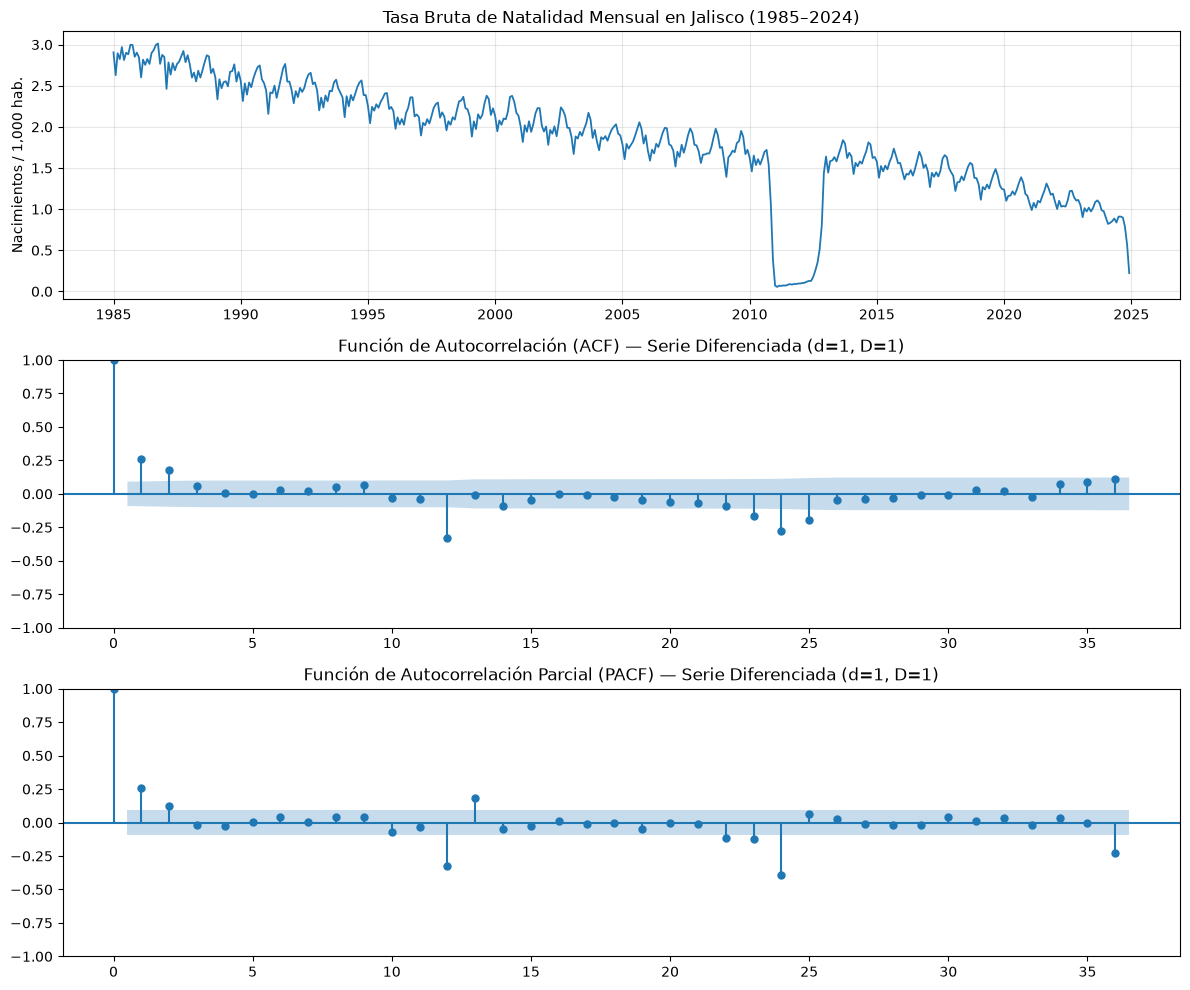

In [23]:
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

df_serie = con.execute("SELECT * FROM vw_serie_nacimientos_mensual").df()
df_serie["fecha"] = pd.to_datetime(df_serie["fecha"])
df_serie = df_serie.set_index("fecha")

def prueba_adf(serie, nombre):
    resultado = adfuller(serie.dropna())
    print(f"[{nombre}] Estadístico ADF: {resultado[0]:.4f} | p-valor: {resultado[1]:.4f}")

print("--- Diagnóstico de Estacionariedad (H0: Serie no estacionaria) ---")
prueba_adf(df_serie["tbn_mensual"], "Serie Original (d=0)")
prueba_adf(df_serie["tbn_mensual"].diff(1), "Primera Diferencia Regular (d=1)")
prueba_adf(df_serie["tbn_mensual"].diff(1).diff(12), "Diferencia Regular + Estacional (d=1, D=1)")

# Gráficas de evolución histórica, ACF y PACF
serie_estacionaria = df_serie["tbn_mensual"].diff(1).diff(12).dropna()

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

axes[0].plot(df_serie.index, df_serie["tbn_mensual"], color="#1f77b4", linewidth=1.3)
axes[0].set_title("Tasa Bruta de Natalidad Mensual en Jalisco (1985–2024)")
axes[0].set_ylabel("Nacimientos / 1,000 hab.")
axes[0].grid(alpha=0.3)

plot_acf(serie_estacionaria, lags=36, ax=axes[1])
axes[1].set_title("Función de Autocorrelación (ACF) — Serie Diferenciada (d=1, D=1)")

plot_pacf(serie_estacionaria, lags=36, ax=axes[2])
axes[2].set_title("Función de Autocorrelación Parcial (PACF) — Serie Diferenciada (d=1, D=1)")

plt.tight_layout()
plt.show()

In [24]:
print(con.execute("""
    SELECT ano_reg, ano_nac, date_nac, COUNT(*) AS filas
    FROM read_parquet('natalidad_optimizada.parquet')
    WHERE TRY_CAST(ent_resid AS INTEGER) = 14
      AND TRY_CAST(ano_reg AS INTEGER) IN (2011, 2012)
    GROUP BY 1, 2, 3
    ORDER BY filas DESC
    LIMIT 10
""").df().to_string(index=False))

 ano_reg  ano_nac   date_nac  filas
    2012     2012 2012-99-03   4510
    2011     2011 2011-99-01   4478
    2011     2011 2011-99-15   4419
    2011     2011 2011-99-07   4416
    2012     2012 2012-99-10   4403
    2011     2011 2011-99-11   4398
    2011     2011 2011-99-18   4393
    2011     2011 2011-99-04   4378
    2012     2012 2012-99-12   4376
    2012     2012 2012-99-04   4374


In [25]:
# 1. Actualizar dim_tiempo incluyendo mes = 0 para registros con mes no especificado
con.execute("""
CREATE OR REPLACE TABLE dim_tiempo AS
SELECT
    (anio * 100 + mes) AS id_tiempo,
    anio,
    mes,
    CASE WHEN mes BETWEEN 1 AND 12 THEN MAKE_DATE(anio, mes, 1) ELSE NULL END AS fecha,
    CASE WHEN mes BETWEEN 1 AND 12 THEN ((mes - 1) // 3) + 1 ELSE NULL END AS trimestre,
    (anio // 10) * 10 AS decada,
    CASE WHEN anio IN (2020, 2021) THEN TRUE ELSE FALSE END AS es_periodo_pandemia
FROM range(1985, 2025) t1(anio)
CROSS JOIN range(0, 13) t2(mes);
""")

# 2. Reconstruir silver_jalisco conservando los registros con mes_nac = 99 como NULL
con.execute("""
CREATE OR REPLACE TABLE silver_jalisco AS
WITH base_limpia AS (
    SELECT
        CAST(TRY_CAST(ano_reg AS DOUBLE) AS INTEGER) AS anio_registro,
        CAST(TRY_CAST(ano_nac AS DOUBLE) AS INTEGER) AS anio_nac,
        CASE 
            WHEN CAST(TRY_CAST(mes_nac AS DOUBLE) AS INTEGER) BETWEEN 1 AND 12 
                THEN CAST(TRY_CAST(mes_nac AS DOUBLE) AS INTEGER)
            ELSE NULL 
        END AS mes_nac,
        LPAD(TRIM(CAST(mun_resid AS VARCHAR)), 3, '0') AS cve_municipio,
        
        NULLIF(CAST(TRY_CAST(edad_madn AS DOUBLE) AS INTEGER), 99) AS edad_madre,
        NULLIF(CAST(TRY_CAST(edad_padn AS DOUBLE) AS INTEGER), 99) AS edad_padre,
        NULLIF(CAST(TRY_CAST(orden_part AS DOUBLE) AS INTEGER), 99) AS orden_parto,
        NULLIF(CAST(TRY_CAST(hijos_vivo AS DOUBLE) AS INTEGER), 99) AS hijos_vivos,
        
        COALESCE(NULLIF(CAST(TRY_CAST(sexo AS DOUBLE) AS INTEGER), 9), 0) AS cod_sexo,
        COALESCE(NULLIF(CAST(TRY_CAST(escol_mad AS DOUBLE) AS INTEGER), 99), 0) AS cod_escolaridad,
        COALESCE(NULLIF(CAST(TRY_CAST(edociv_mad AS DOUBLE) AS INTEGER), 9), 0) AS cod_edociv,
        COALESCE(NULLIF(CAST(TRY_CAST(act_mad AS DOUBLE) AS INTEGER), 9), 0) AS cod_actividad,
        COALESCE(NULLIF(CAST(TRY_CAST(tipo_nac AS DOUBLE) AS INTEGER), 9), 0) AS cod_tipo_parto,
        COALESCE(NULLIF(CAST(TRY_CAST(lugar_part AS DOUBLE) AS INTEGER), 9), 0) AS cod_lugar_parto,
        COALESCE(NULLIF(CAST(TRY_CAST(q_atendio AS DOUBLE) AS INTEGER), 9), 0) AS cod_atendio
    FROM read_parquet('natalidad_optimizada.parquet')
    WHERE TRY_CAST(ent_resid AS INTEGER) = 14
)
SELECT
    *,
    CASE 
        WHEN edad_madre IS NULL THEN 'No especificado'
        WHEN edad_madre < 15 THEN 'Menor de 15'
        WHEN edad_madre BETWEEN 15 AND 19 THEN '15 a 19 años'
        WHEN edad_madre BETWEEN 20 AND 24 THEN '20 a 24 años'
        WHEN edad_madre BETWEEN 25 AND 29 THEN '25 a 29 años'
        WHEN edad_madre BETWEEN 30 AND 34 THEN '30 a 34 años'
        WHEN edad_madre BETWEEN 35 AND 39 THEN '35 a 39 años'
        ELSE '40 años o más'
    END AS grupo_edad_madre
FROM base_limpia
WHERE anio_nac BETWEEN 1985 AND 2024;
""")

# 3. Reconstruir fact_nacimientos asignando mes 00 cuando mes_nac es NULL
con.execute("""
CREATE OR REPLACE TABLE fact_nacimientos AS
SELECT
    (s.anio_nac * 100 + COALESCE(s.mes_nac, 0)) AS id_tiempo,
    COALESCE(m.id_municipio, '999') AS id_municipio,
    pm.id_perfil_madre,
    cp.id_condicion_parto,
    s.anio_registro,
    (s.anio_registro - s.anio_nac) AS rezago_registro_anios,
    s.edad_madre,
    s.edad_padre,
    s.orden_parto,
    s.hijos_vivos
FROM silver_jalisco s
LEFT JOIN dim_municipio m ON s.cve_municipio = m.id_municipio
LEFT JOIN dim_perfil_madre pm 
    ON s.grupo_edad_madre = pm.grupo_edad_madre
    AND s.cod_escolaridad = pm.cod_escolaridad
    AND s.cod_edociv = pm.cod_edociv
    AND s.cod_actividad = pm.cod_actividad
LEFT JOIN dim_condicion_parto cp 
    ON s.cod_sexo = cp.cod_sexo 
    AND s.cod_tipo_parto = cp.cod_tipo_parto
    AND s.cod_lugar_parto = cp.cod_lugar_parto
    AND s.cod_atendio = cp.cod_atendio;
""")

# 4. Actualizar la vista mensual distribuyendo estacionalmente los registros sin mes
con.execute("""
CREATE OR REPLACE VIEW vw_serie_nacimientos_mensual AS
WITH conteos AS (
    SELECT
        t.id_tiempo,
        t.fecha,
        t.anio,
        t.mes,
        t.trimestre,
        t.decada,
        t.es_periodo_pandemia,
        COUNT(f.id_tiempo) AS nac_conocidos
    FROM dim_tiempo t
    LEFT JOIN fact_nacimientos f ON t.id_tiempo = f.id_tiempo
    WHERE t.mes BETWEEN 1 AND 12
    GROUP BY t.id_tiempo, t.fecha, t.anio, t.mes, t.trimestre, t.decada, t.es_periodo_pandemia
),
sin_mes AS (
    SELECT
        (id_tiempo // 100) AS anio,
        COUNT(*) AS nac_sin_mes
    FROM fact_nacimientos
    WHERE (id_tiempo % 100) = 0
    GROUP BY 1
),
pesos_estacionales AS (
    SELECT
        mes,
        SUM(nac_conocidos) * 1.0 / SUM(SUM(nac_conocidos)) OVER () AS peso_mes
    FROM conteos
    WHERE anio NOT IN (2011, 2012, 2024)
    GROUP BY mes
)
SELECT
    c.id_tiempo,
    c.fecha,
    c.anio,
    c.mes,
    c.trimestre,
    c.decada,
    c.es_periodo_pandemia,
    CAST(c.nac_conocidos + ROUND(COALESCE(s.nac_sin_mes, 0) * w.peso_mes) AS BIGINT) AS nacimientos_ocurridos,
    p.poblacion_total,
    ROUND((CAST(c.nac_conocidos + ROUND(COALESCE(s.nac_sin_mes, 0) * w.peso_mes) AS DOUBLE) * 1000.0) / p.poblacion_total, 4) AS tbn_mensual
FROM conteos c
LEFT JOIN sin_mes s ON c.anio = s.anio
JOIN pesos_estacionales w ON c.mes = w.mes
LEFT JOIN dim_poblacion_jalisco p ON c.anio = p.anio
ORDER BY c.id_tiempo;
""")

print("Total registros en fact_nacimientos:", con.execute("SELECT COUNT(*) FROM fact_nacimientos").fetchone()[0])

Total registros en fact_nacimientos: 6151739


In [26]:
# 1. Actualizar dim_perfil_madre con todas las columnas de silver_jalisco
con.execute("""
CREATE OR REPLACE TABLE dim_perfil_madre AS
WITH combinaciones AS (
    SELECT DISTINCT
        grupo_edad_madre,
        cod_escolaridad,
        cod_edociv,
        CASE cod_edociv
            WHEN 1 THEN 'Soltera'
            WHEN 2 THEN 'Casada'
            WHEN 3 THEN 'Unión libre'
            WHEN 4 THEN 'Separada / Divorciada'
            WHEN 5 THEN 'Viuda'
            ELSE 'No especificado'
        END AS estado_civil,
        cod_actividad,
        CASE cod_actividad
            WHEN 1 THEN 'Trabaja'
            WHEN 2 THEN 'No trabaja'
            ELSE 'No especificado'
        END AS condicion_actividad
    FROM silver_jalisco
)
SELECT 
    ROW_NUMBER() OVER (ORDER BY grupo_edad_madre, cod_escolaridad, cod_edociv, cod_actividad) AS id_perfil_madre,
    *
FROM combinaciones;
""")

# 2. Actualizar dim_condicion_parto
con.execute("""
CREATE OR REPLACE TABLE dim_condicion_parto AS
WITH combinaciones AS (
    SELECT DISTINCT
        cod_sexo,
        CASE cod_sexo
            WHEN 1 THEN 'Hombre'
            WHEN 2 THEN 'Mujer'
            ELSE 'No especificado'
        END AS sexo,
        cod_tipo_parto,
        CASE cod_tipo_parto
            WHEN 1 THEN 'Simple'
            WHEN 2 THEN 'Doble (Gemelar)'
            WHEN 3 THEN 'Triple o más'
            ELSE 'No especificado'
        END AS tipo_parto,
        cod_lugar_parto,
        CASE cod_lugar_parto
            WHEN 1 THEN 'Hospital / Clínica'
            WHEN 2 THEN 'Domicilio'
            ELSE 'Otro / No especificado'
        END AS lugar_parto,
        cod_atendio,
        CASE cod_atendio
            WHEN 1 THEN 'Médico'
            WHEN 2 THEN 'Enfermera / Partera'
            ELSE 'Otro / No especificado'
        END AS persona_atendio
    FROM silver_jalisco
)
SELECT 
    ROW_NUMBER() OVER (ORDER BY cod_sexo, cod_tipo_parto, cod_lugar_parto, cod_atendio) AS id_condicion_parto,
    *
FROM combinaciones;
""")

# 3. Reconstruir fact_nacimientos asignando mes 00 cuando mes_nac es NULL
con.execute("""
CREATE OR REPLACE TABLE fact_nacimientos AS
SELECT
    (s.anio_nac * 100 + COALESCE(s.mes_nac, 0)) AS id_tiempo,
    COALESCE(m.id_municipio, '999') AS id_municipio,
    pm.id_perfil_madre,
    cp.id_condicion_parto,
    s.anio_registro,
    (s.anio_registro - s.anio_nac) AS rezago_registro_anios,
    s.edad_madre,
    s.edad_padre,
    s.orden_parto,
    s.hijos_vivos
FROM silver_jalisco s
LEFT JOIN dim_municipio m ON s.cve_municipio = m.id_municipio
LEFT JOIN dim_perfil_madre pm 
    ON s.grupo_edad_madre = pm.grupo_edad_madre
    AND s.cod_escolaridad = pm.cod_escolaridad
    AND s.cod_edociv = pm.cod_edociv
    AND s.cod_actividad = pm.cod_actividad
LEFT JOIN dim_condicion_parto cp 
    ON s.cod_sexo = cp.cod_sexo 
    AND s.cod_tipo_parto = cp.cod_tipo_parto
    AND s.cod_lugar_parto = cp.cod_lugar_parto
    AND s.cod_atendio = cp.cod_atendio;
""")

# 4. Actualizar la vista mensual con ponderación estacional para 2011-2012
con.execute("""
CREATE OR REPLACE VIEW vw_serie_nacimientos_mensual AS
WITH conteos AS (
    SELECT
        t.id_tiempo,
        t.fecha,
        t.anio,
        t.mes,
        t.trimestre,
        t.decada,
        t.es_periodo_pandemia,
        COUNT(f.id_tiempo) AS nac_conocidos
    FROM dim_tiempo t
    LEFT JOIN fact_nacimientos f ON t.id_tiempo = f.id_tiempo
    WHERE t.mes BETWEEN 1 AND 12
    GROUP BY t.id_tiempo, t.fecha, t.anio, t.mes, t.trimestre, t.decada, t.es_periodo_pandemia
),
sin_mes AS (
    SELECT
        (id_tiempo // 100) AS anio,
        COUNT(*) AS nac_sin_mes
    FROM fact_nacimientos
    WHERE (id_tiempo % 100) = 0
    GROUP BY 1
),
pesos_estacionales AS (
    SELECT
        mes,
        SUM(nac_conocidos) * 1.0 / SUM(SUM(nac_conocidos)) OVER () AS peso_mes
    FROM conteos
    WHERE anio NOT IN (2011, 2012, 2024)
    GROUP BY mes
)
SELECT
    c.id_tiempo,
    c.fecha,
    c.anio,
    c.mes,
    c.trimestre,
    c.decada,
    c.es_periodo_pandemia,
    CAST(c.nac_conocidos + ROUND(COALESCE(s.nac_sin_mes, 0) * w.peso_mes) AS BIGINT) AS nacimientos_ocurridos,
    p.poblacion_total,
    ROUND((CAST(c.nac_conocidos + ROUND(COALESCE(s.nac_sin_mes, 0) * w.peso_mes) AS DOUBLE) * 1000.0) / p.poblacion_total, 4) AS tbn_mensual
FROM conteos c
LEFT JOIN sin_mes s ON c.anio = s.anio
JOIN pesos_estacionales w ON c.mes = w.mes
LEFT JOIN dim_poblacion_jalisco p ON c.anio = p.anio
ORDER BY c.id_tiempo;
""")

print("Total registros en fact_nacimientos:", con.execute("SELECT COUNT(*) FROM fact_nacimientos").fetchone()[0])

Total registros en fact_nacimientos: 6151739


C:\Users\qorex\AppData\Local\Temp\ipykernel_19768\2895367558.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res_adf = adfuller(df_serie["tbn_mensual"].diff(1).diff(12).dropna())


ADF (d=1, D=1) corregido: -10.0751 | p-valor: 1.2300e-17


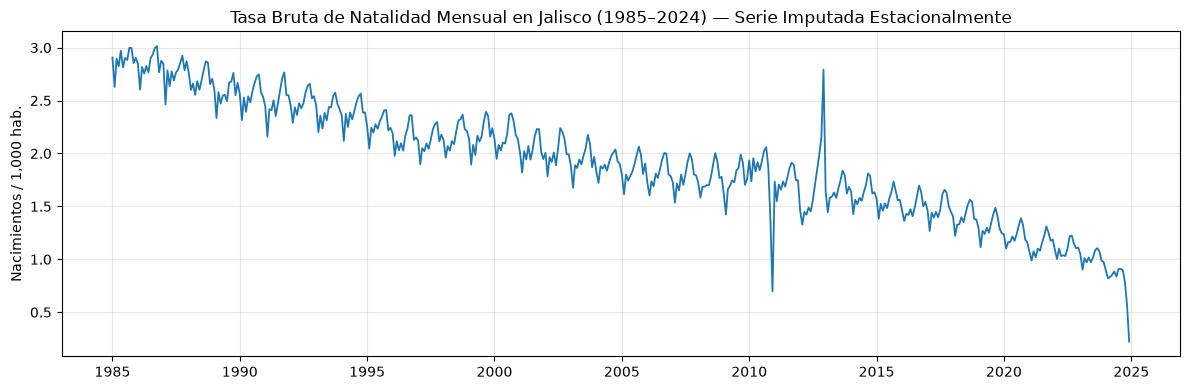

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

df_serie = con.execute("SELECT * FROM vw_serie_nacimientos_mensual").df()
df_serie["fecha"] = pd.to_datetime(df_serie["fecha"])
df_serie = df_serie.set_index("fecha")

res_adf = adfuller(df_serie["tbn_mensual"].diff(1).diff(12).dropna())
print(f"ADF (d=1, D=1) corregido: {res_adf[0]:.4f} | p-valor: {res_adf[1]:.4e}")

plt.figure(figsize=(12, 4))
plt.plot(df_serie.index, df_serie["tbn_mensual"], color="#1f77b4", linewidth=1.3)
plt.title("Tasa Bruta de Natalidad Mensual en Jalisco (1985–2024) — Serie Imputada Estacionalmente")
plt.ylabel("Nacimientos / 1,000 hab.")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
con.execute("""
CREATE OR REPLACE VIEW vw_serie_nacimientos_mensual AS
WITH conteos AS (
    SELECT
        t.id_tiempo,
        t.fecha,
        t.anio,
        t.mes,
        t.trimestre,
        t.decada,
        t.es_periodo_pandemia,
        COUNT(f.id_tiempo) AS nac_conocidos
    FROM dim_tiempo t
    LEFT JOIN fact_nacimientos f ON t.id_tiempo = f.id_tiempo
    WHERE t.mes BETWEEN 1 AND 12
    GROUP BY t.id_tiempo, t.fecha, t.anio, t.mes, t.trimestre, t.decada, t.es_periodo_pandemia
),
resumen_anual AS (
    SELECT
        (id_tiempo // 100) AS anio,
        COUNT(*) AS total_anual,
        SUM(CASE WHEN (id_tiempo % 100) = 0 THEN 1 ELSE 0 END) AS nac_sin_mes
    FROM fact_nacimientos
    GROUP BY 1
),
pesos_estacionales AS (
    SELECT
        mes,
        SUM(nac_conocidos) * 1.0 / SUM(SUM(nac_conocidos)) OVER () AS peso_mes
    FROM conteos
    WHERE anio NOT IN (2011, 2012, 2024)
    GROUP BY mes
),
ajustado AS (
    SELECT
        c.id_tiempo,
        c.fecha,
        c.anio,
        c.mes,
        c.trimestre,
        c.decada,
        c.es_periodo_pandemia,
        CASE 
            WHEN (r.nac_sin_mes * 1.0 / NULLIF(r.total_anual, 0)) > 0.10 
                THEN CAST(ROUND(r.total_anual * w.peso_mes) AS BIGINT)
            ELSE CAST(c.nac_conocidos + ROUND(r.nac_sin_mes * w.peso_mes) AS BIGINT)
        END AS nacimientos_ocurridos,
        p.poblacion_total
    FROM conteos c
    JOIN resumen_anual r ON c.anio = r.anio
    JOIN pesos_estacionales w ON c.mes = w.mes
    LEFT JOIN dim_poblacion_jalisco p ON c.anio = p.anio
)
SELECT
    id_tiempo,
    fecha,
    anio,
    mes,
    trimestre,
    decada,
    es_periodo_pandemia,
    nacimientos_ocurridos,
    poblacion_total,
    ROUND((nacimientos_ocurridos * 1000.0) / poblacion_total, 4) AS tbn_mensual
FROM ajustado
ORDER BY id_tiempo;
""")

MACHINE LEARNING

COMPLEJIDAD COMPUTACIONAL
Bloque 1: Benchmark de Datos — DuckDB (OLAP Columnar) vs. Pandas (En Memoria)

In [49]:
import time
import tracemalloc
import duckdb
import numpy as np
import pandas as pd

con = duckdb.connect("inegi_analytics.db")

# Ventanas históricas a evaluar (5, 10, 20 y 40 años)
ventanas = [
    ("5 años (1985–1989)", 1989),
    ("10 años (1985–1994)", 1994),
    ("20 años (1985–2004)", 2004),
    ("40 años (1985–2024)", 2024),
]

resultados_datos = []

for etiqueta, anio_fin in ventanas:
    # Contar volumen real de registros N en esa ventana
    n_registros = con.execute(f"""
        SELECT COUNT(*) 
        FROM fact_nacimientos f
        JOIN dim_tiempo t ON f.id_tiempo = t.id_tiempo
        WHERE t.anio <= {anio_fin}
    """).fetchone()[0]

    # --- 1. BENCHMARK DUCKDB (Ejecución Columnar Vectorizada en C++) ---
    tracemalloc.start()
    t0 = time.perf_counter()
    
    res_duck = con.execute(f"""
        SELECT 
            t.decada,
            m.zona_geografica,
            COUNT(*) AS total_nacimientos,
            AVG(f.edad_madre) AS promedio_edad
        FROM fact_nacimientos f
        JOIN dim_tiempo t ON f.id_tiempo = t.id_tiempo
        JOIN dim_municipio m ON f.id_municipio = m.id_municipio
        WHERE t.anio <= {anio_fin}
        GROUP BY t.decada, m.zona_geografica
    """).df()
    
    t_duck = time.perf_counter() - t0
    _, pico_mem_duck = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    # --- 2. BENCHMARK PANDAS (Carga a RAM + Merge + GroupBy) ---
    tracemalloc.start()
    t0 = time.perf_counter()
    
    df_fact = con.execute(f"""
        SELECT f.id_tiempo, f.id_municipio, f.edad_madre
        FROM fact_nacimientos f
        JOIN dim_tiempo t ON f.id_tiempo = t.id_tiempo
        WHERE t.anio <= {anio_fin}
    """).df()
    df_tiempo = con.execute("SELECT id_tiempo, decada FROM dim_tiempo").df()
    df_mun = con.execute("SELECT id_municipio, zona_geografica FROM dim_municipio").df()
    
    res_pandas = (
        df_fact
        .merge(df_tiempo, on="id_tiempo", how="left")
        .merge(df_mun, on="id_municipio", how="left")
        .groupby(["decada", "zona_geografica"], as_index=False)
        .agg(total_nacimientos=("edad_madre", "count"), promedio_edad=("edad_madre", "mean"))
    )
    
    t_pandas = time.perf_counter() - t0
    _, pico_mem_pandas = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    
    # Liberar memoria intermedia antes de la siguiente iteración
    del df_fact, df_tiempo, df_mun

    resultados_datos.append({
        "Ventana": etiqueta,
        "Registros (N)": n_registros,
        "Tiempo DuckDB (s)": round(t_duck, 4),
        "Tiempo Pandas (s)": round(t_pandas, 4),
        "Speedup (x)": round(t_pandas / max(t_duck, 1e-6), 1),
        "RAM Python DuckDB (MB)": round(pico_mem_duck / (1024 ** 2), 2),
        "RAM Python Pandas (MB)": round(pico_mem_pandas / (1024 ** 2), 2),
    })

df_bench_datos = pd.DataFrame(resultados_datos)
print("--- Complejidad Empírica en Procesamiento de Datos (Jalisco) ---")
print(df_bench_datos.to_string(index=False))

--- Complejidad Empírica en Procesamiento de Datos (Jalisco) ---
            Ventana  Registros (N)  Tiempo DuckDB (s)  Tiempo Pandas (s)  Speedup (x)  RAM Python DuckDB (MB)  RAM Python Pandas (MB)
 5 años (1985–1989)         855876             0.1877             3.6481         19.4                    0.14                   89.02
10 años (1985–1994)        1712448             0.0464             5.3357        115.0                    0.14                  178.05
20 años (1985–2004)        3329004             0.0510            10.0693        197.6                    0.14                  346.09
40 años (1985–2024)        5830641             0.0712            17.2017        241.6                    0.14                  606.14


Bloque 2: Benchmark de Modelos (SARIMA vs. Regresión Bayesiana) y Visualización


--- Complejidad Empírica en Entrenamiento de Modelos ---
 Meses (T)  Años aprox.  Tiempo Bayesiana (ms)  Tiempo SARIMA (ms)  Ratio SARIMA / Bayes
        60          5.0                  5.801              486.76                  83.9
       120         10.0                  1.424              412.65                 289.9
       240         20.0                  1.561              664.08                 425.5
       474         39.5                  1.580              913.26                 578.0


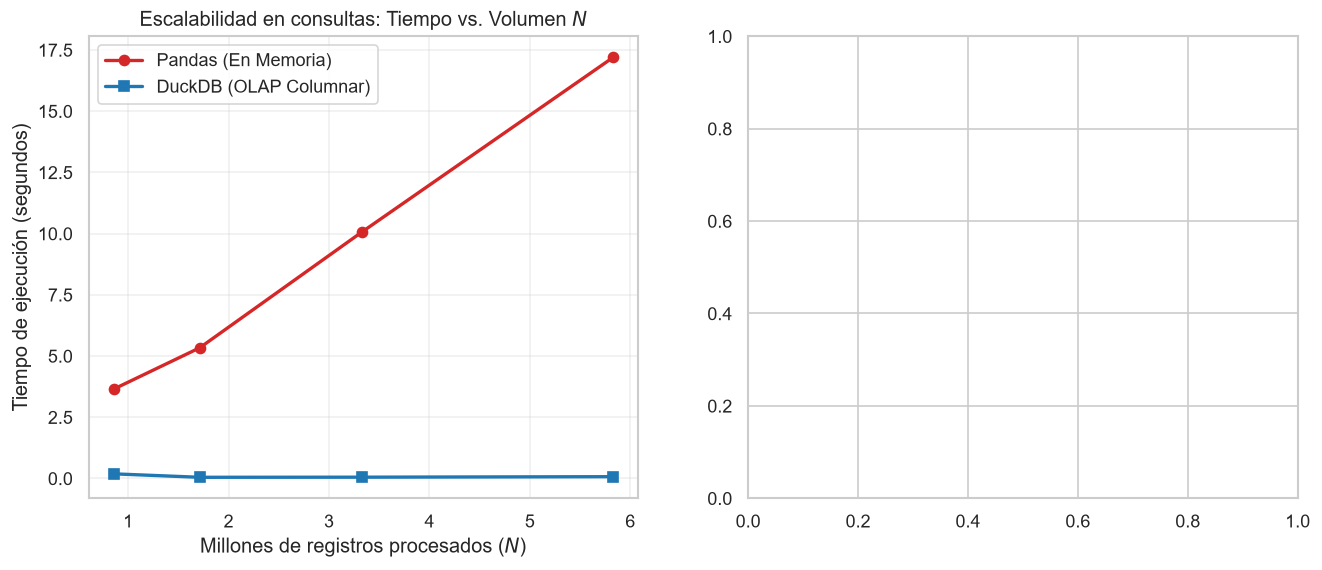

In [50]:
import warnings
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.linear_model import BayesianRidge

warnings.filterwarnings("ignore")

# Cargar serie completa validada (hasta junio 2024)
df_serie = con.execute("SELECT * FROM vw_serie_nacimientos_mensual").df()
df_serie["fecha"] = pd.to_datetime(df_serie["fecha"])
df_serie = df_serie[df_serie["fecha"] <= "2024-06-01"].sort_values("fecha").reset_index(drop=True)
df_serie["t"] = np.arange(len(df_serie))

X_meses = pd.get_dummies(df_serie["mes"], prefix="mes", drop_first=True, dtype=float)
X_full = pd.concat([df_serie[["t"]], X_meses], axis=1)
y_full = df_serie["tbn_mensual"].values

longitudes_T = [60, 120, 240, len(y_full)]  # 5, 10, 20 y ~39.5 años
resultados_ml = []

for T in longitudes_T:
    X_sub = X_full.iloc[:T]
    y_sub = y_full[:T]

    # 1. Tiempo entrenamiento Regresión Lineal Bayesiana (promediado en 20 corridas)
    t0 = time.perf_counter()
    for _ in range(20):
        BayesianRidge().fit(X_sub, y_sub)
    t_bayes = (time.perf_counter() - t0) / 20.0

    # 2. Tiempo entrenamiento SARIMA (1,1,1)(1,1,1,12)
    t0 = time.perf_counter()
    SARIMAX(
        y_sub,
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False, maxiter=100)
    t_sarima = time.perf_counter() - t0

    resultados_ml.append({
        "Meses (T)": T,
        "Años aprox.": round(T / 12, 1),
        "Tiempo Bayesiana (ms)": round(t_bayes * 1000, 3),
        "Tiempo SARIMA (ms)": round(t_sarima * 1000, 2),
        "Ratio SARIMA / Bayes": round(t_sarima / max(t_bayes, 1e-7), 1)
    })

df_bench_ml = pd.DataFrame(resultados_ml)
print("\n--- Complejidad Empírica en Entrenamiento de Modelos ---")
print(df_bench_ml.to_string(index=False))

# --- GRÁFICAS DE ESCALABILIDAD COMPUTACIONAL ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel 1: Procesamiento de datos O(N)
axes[0].plot(df_bench_datos["Registros (N)"] / 1e6, df_bench_datos["Tiempo Pandas (s)"],
             marker="o", color="#d62728", linewidth=2, label="Pandas (En Memoria)")
axes[0].plot(df_bench_datos["Registros (N)"] / 1e6, df_bench_datos["Tiempo DuckDB (s)"],
             marker="s", color="#1f77b4", linewidth=2, label="DuckDB (OLAP Columnar)")
axes[0].set_title("Escalabilidad en consultas: Tiempo vs. Volumen $N$")
axes[0].set_xlabel("Millones de registros procesados ($N$)")
axes[0].set_ylabel("Tiempo de ejecución (segundos)")
axes[0].legend()
axes[0].grid(alpha=0.3)


In [ ]:
3. Código de Machine Learning (3 Modelos + Proyección 2025–2030)

--- Comparativa de desempeño predictivo (Validación 2019–2024) ---
                                 Modelo  MAPE Train (%)  MAE Test  RMSE Test  MAPE Test (%)
1. Baseline (Regresión Lineal Múltiple)            3.06    0.1159     0.1343          10.88
  2. Random Forest (Autorregresivo d=1)            1.24    0.2926     0.3501          28.27
            3. SARIMA (1,1,1)(1,1,1,12)            1.56    0.1060     0.1205           9.94


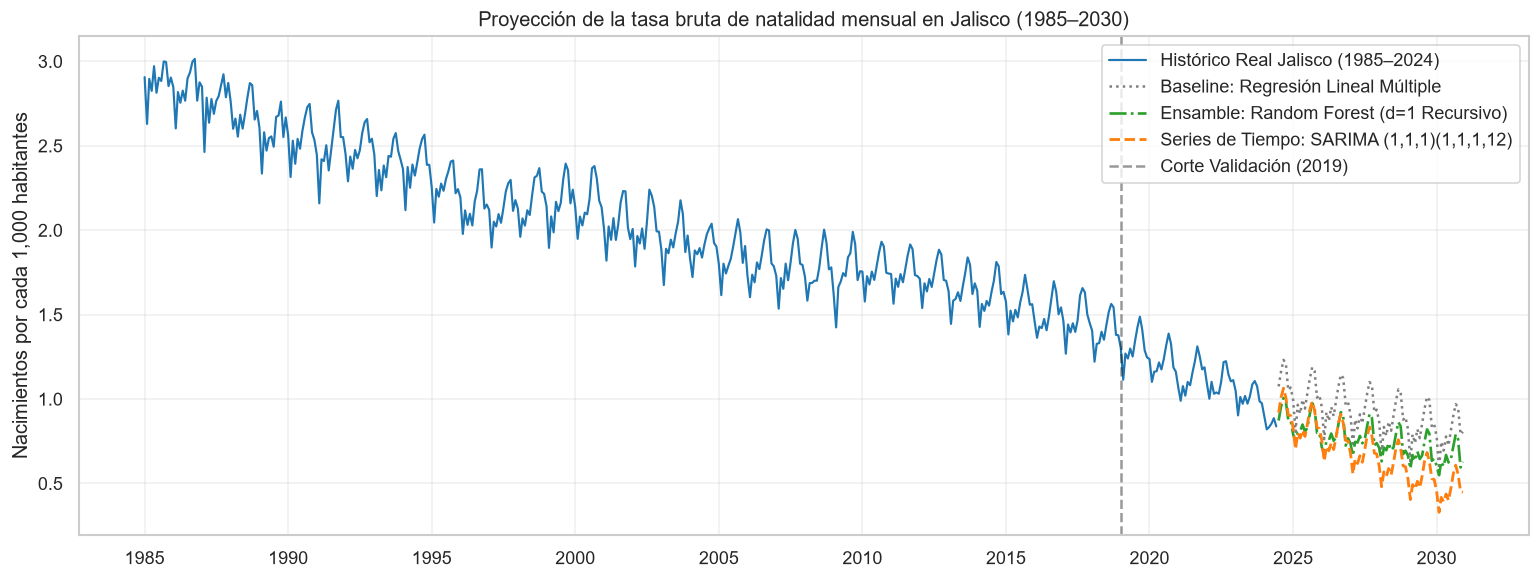

In [5]:
import warnings
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")

# 1. Cargar serie mensual consolidada desde DuckDB
con = duckdb.connect("inegi_analytics.db")
df = con.execute("SELECT * FROM vw_serie_nacimientos_mensual").df()
df["fecha"] = pd.to_datetime(df["fecha"])
df = df.sort_values("fecha").reset_index(drop=True)
df["t"] = np.arange(len(df))

# Partición cronológica estricta (Train: 1985-2018 | Test: 2019-jun 2024)
mask_train = df["anio"] <= 2018
mask_test = (df["anio"] >= 2019) & (df["fecha"] <= "2024-06-01")
mask_valido = df["fecha"] <= "2024-06-01"

y_train = df.loc[mask_train, "tbn_mensual"].values
y_test = df.loc[mask_test, "tbn_mensual"].values
y_valido = df.loc[mask_valido, "tbn_mensual"].values

# ==============================================================================
# MODELO 1: Baseline Lineal (Regresión Lineal Múltiple: Tendencia + Estacionalidad)
# ==============================================================================
X_meses = pd.get_dummies(df["mes"], prefix="mes", drop_first=True, dtype=float)
X_ols = pd.concat([df[["t"]], X_meses], axis=1)

ols = LinearRegression().fit(X_ols[mask_train], y_train)
pred_train_ols = ols.predict(X_ols[mask_train])
pred_test_ols = ols.predict(X_ols[mask_test])

# ==============================================================================
# MODELO 2: Ensamble de Árboles (Random Forest Autorregresivo Diferenciado)
# ==============================================================================
def preparar_datos_rf(serie_y, meses):
    s_y = pd.Series(serie_y)
    dy = s_y.diff(1)
    df_feat = pd.DataFrame({
        "dy_lag1": dy.shift(1),
        "dy_lag12": dy.shift(12),
    })
    for m in range(2, 13):
        df_feat[f"mes_{m}"] = (np.array(meses) == m).astype(float)
    df_feat["target_dy"] = dy
    df_limpio = df_feat.dropna().reset_index(drop=True)
    X_rf = df_limpio.drop(columns=["target_dy"]).values
    y_rf = df_limpio["target_dy"].values
    return X_rf, y_rf

def predecir_rf_recursivo(modelo_rf, y_historia, fechas_objetivo):
    y_buf = list(y_historia)
    dy_buf = list(np.diff(y_historia))
    predicciones = []
    for fecha_obj in fechas_objetivo:
        m = fecha_obj.month
        fila = [dy_buf[-1], dy_buf[-12]] + [1.0 if m == k else 0.0 for k in range(2, 13)]
        dy_hat = modelo_rf.predict([fila])[0]
        y_hat = y_buf[-1] + dy_hat
        dy_buf.append(dy_hat)
        y_buf.append(y_hat)
        predicciones.append(y_hat)
    return np.array(predicciones)

X_rf_train, y_rf_train = preparar_datos_rf(y_train, df.loc[mask_train, "mes"].values)
rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
).fit(X_rf_train, y_rf_train)

# Ajuste dentro de muestra (Train) y pronóstico recursivo en Test (66 meses)
pred_train_rf = y_train[12:-1] + rf.predict(X_rf_train)
pred_test_rf = predecir_rf_recursivo(rf, y_train, df.loc[mask_test, "fecha"])

# ==============================================================================
# MODELO 3: Series de Tiempo SARIMA (1, 1, 1)(1, 1, 1, 12)
# ==============================================================================
sarima = SARIMAX(
    y_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False, maxiter=200)

pred_train_sarima = sarima.fittedvalues[13:]
pred_test_sarima = sarima.forecast(steps=len(y_test))

# ==============================================================================
# TABLA COMPARATIVA DE MÉTRICAS (TRAIN VS. TEST)
# ==============================================================================
def evaluar_modelo(y_tr_real, y_tr_pred, y_te_real, y_te_pred, nombre):
    mape_train = np.mean(np.abs((y_tr_real - y_tr_pred) / y_tr_real)) * 100
    mae_test = mean_absolute_error(y_te_real, y_te_pred)
    rmse_test = root_mean_squared_error(y_te_real, y_te_pred)
    mape_test = np.mean(np.abs((y_te_real - y_te_pred) / y_te_real)) * 100
    return {
        "Modelo": nombre,
        "MAPE Train (%)": round(mape_train, 2),
        "MAE Test": round(mae_test, 4),
        "RMSE Test": round(rmse_test, 4),
        "MAPE Test (%)": round(mape_test, 2)
    }

tabla_ml = pd.DataFrame([
    evaluar_modelo(y_train, pred_train_ols, y_test, pred_test_ols, "1. Baseline (Regresión Lineal Múltiple)"),
    evaluar_modelo(y_train[13:], pred_train_rf, y_test, pred_test_rf, "2. Random Forest (Autorregresivo d=1)"),
    evaluar_modelo(y_train[13:], pred_train_sarima, y_test, pred_test_sarima, "3. SARIMA (1,1,1)(1,1,1,12)")
])
print("--- Comparativa de desempeño predictivo (Validación 2019–2024) ---")
print(tabla_ml.to_string(index=False))

# ==============================================================================
# RE-ENTRENAMIENTO COMPLETO Y PROYECCIÓN 2025–2030
# ==============================================================================
fechas_futuras = pd.date_range(start="2024-07-01", end="2030-12-01", freq="MS")
t_futuro = np.arange(len(df), len(df) + len(fechas_futuras))
X_fut_ols = pd.concat([
    pd.DataFrame({"t": t_futuro}),
    pd.get_dummies(fechas_futuras.month, prefix="mes", drop_first=True, dtype=float)
], axis=1)

# 1. Proyección OLS
ols_final = LinearRegression().fit(X_ols[mask_valido], y_valido)
proy_ols = ols_final.predict(X_fut_ols)

# 2. Proyección Random Forest
X_rf_full, y_rf_full = preparar_datos_rf(y_valido, df.loc[mask_valido, "mes"].values)
rf_final = RandomForestRegressor(
    n_estimators=300, max_depth=8, min_samples_leaf=3, random_state=42, n_jobs=-1
).fit(X_rf_full, y_rf_full)
proy_rf = predecir_rf_recursivo(rf_final, y_valido, fechas_futuras)

# 3. Proyección SARIMA
sarima_final = SARIMAX(
    y_valido, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False, enforce_invertibility=False
).fit(disp=False, maxiter=200)
proy_sarima = sarima_final.forecast(steps=len(fechas_futuras))

# Gráfica comparativa de los 3 modelos
plt.figure(figsize=(13, 5))
plt.plot(df.loc[mask_valido, "fecha"], y_valido, label="Histórico Real Jalisco (1985–2024)", color="#1f77b4", linewidth=1.3)
plt.plot(fechas_futuras, proy_ols, label="Baseline: Regresión Lineal Múltiple", color="#7f7f7f", linestyle=":", linewidth=1.5)
plt.plot(fechas_futuras, proy_rf, label="Ensamble: Random Forest (d=1 Recursivo)", color="#2ca02c", linestyle="-.", linewidth=1.6)
plt.plot(fechas_futuras, proy_sarima, label="Series de Tiempo: SARIMA (1,1,1)(1,1,1,12)", color="#ff7f0e", linestyle="--", linewidth=1.7)
plt.axvline(pd.to_datetime("2019-01-01"), color="black", alpha=0.4, linestyle="--", label="Corte Validación (2019)")
plt.title("Proyección de la tasa bruta de natalidad mensual en Jalisco (1985–2030)")
plt.ylabel("Nacimientos por cada 1,000 habitantes")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

4. Actualización del Benchmark de Complejidad Computacional ($O(T)$)

,Longitud_T,SARIMA_ms,Random_Forest_ms,OLS_ms
0,60,276.48,219.78,2.45
1,120,459.66,205.98,0.70
2,240,701.52,281.59,0.74
3,474,1253.83,547.90,0.93


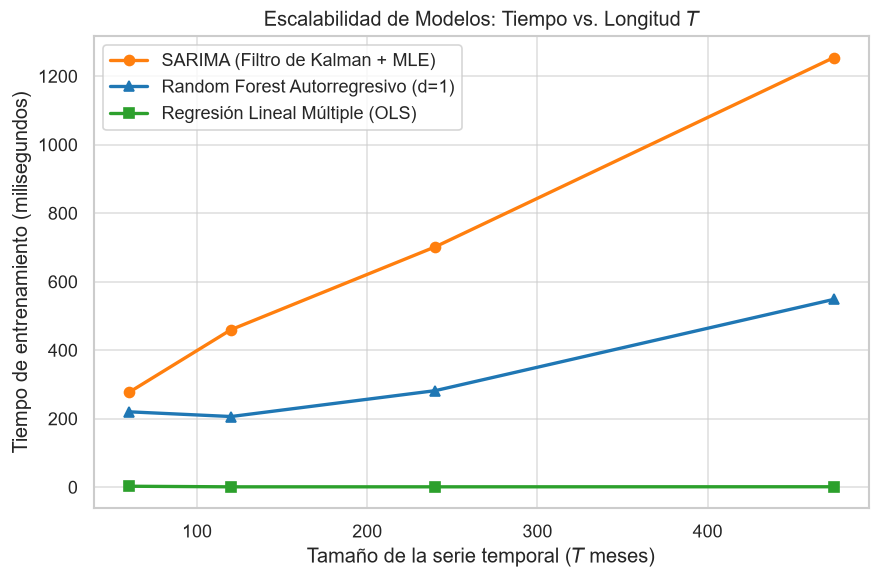

In [12]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.statespace.sarimax import SARIMAX

longitudes_T = [60, 120, 240, len(y_valido)]
resultados_ml_bench = []
X_ols_arr = np.asarray(X_ols)

# Warm-up inicial para evitar latencia de primera ejecución
_ = SARIMAX(
    y_valido[:60],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False, maxiter=20)

for T in longitudes_T:
    y_sub = y_valido[:T]
    X_ols_sub = X_ols_arr[mask_valido][:T]
    meses_sub = df.loc[mask_valido, "mes"].values[:T]

    # 1. Tiempo Regresión Lineal Múltiple (promedio 20 corridas)
    tiempos_ols = []
    for _ in range(20):
        t0 = time.perf_counter()
        LinearRegression().fit(X_ols_sub, y_sub)
        tiempos_ols.append((time.perf_counter() - t0) * 1000)

    # 2. Tiempo Random Forest Autorregresivo (d=1, promedio 5 corridas)
    dy_sub = np.diff(y_sub)
    lags = 12
    X_rf_sub = np.array([dy_sub[i - lags:i] for i in range(lags, len(dy_sub))])
    y_rf_sub = dy_sub[lags:]

    tiempos_rf = []
    for _ in range(5):
        t0 = time.perf_counter()
        RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=1).fit(X_rf_sub, y_rf_sub)
        tiempos_rf.append((time.perf_counter() - t0) * 1000)

    # 3. Tiempo SARIMA(1,1,1)(1,1,1)12 (promedio 3 corridas)
    tiempos_sarima = []
    for _ in range(3):
        t0 = time.perf_counter()
        SARIMAX(
            y_sub,
            order=(1, 1, 1),
            seasonal_order=(1, 1, 1, 12),
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit(disp=False, maxiter=50)
        tiempos_sarima.append((time.perf_counter() - t0) * 1000)

    resultados_ml_bench.append({
        "Longitud_T": T,
        "SARIMA_ms": np.mean(tiempos_sarima),
        "Random_Forest_ms": np.mean(tiempos_rf),
        "OLS_ms": np.mean(tiempos_ols)
    })

df_ml_bench = pd.DataFrame(resultados_ml_bench)
display(df_ml_bench.round(2))

# Gráfica actualizada de escalabilidad temporal
plt.figure(figsize=(7.5, 5.0), dpi=120)
plt.plot(df_ml_bench["Longitud_T"], df_ml_bench["SARIMA_ms"], "o-", color="#ff7f0e", lw=2, label="SARIMA (Filtro de Kalman + MLE)")
plt.plot(df_ml_bench["Longitud_T"], df_ml_bench["Random_Forest_ms"], "^-", color="#1f77b4", lw=2, label="Random Forest Autorregresivo (d=1)")
plt.plot(df_ml_bench["Longitud_T"], df_ml_bench["OLS_ms"], "s-", color="#2ca02c", lw=2, label="Regresión Lineal Múltiple (OLS)")

plt.title("Escalabilidad de Modelos: Tiempo vs. Longitud $T$")
plt.xlabel("Tamaño de la serie temporal ($T$ meses)")
plt.ylabel("Tiempo de entrenamiento (milisegundos)")
plt.grid(True, alpha=0.6)
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig("graficas_eda/escalabilidad_modelos_T.png", dpi=300, bbox_inches="tight")
plt.show()

--- Complejidad Empírica en Entrenamiento (3 Modelos) ---
 Meses (T)  OLS (ms)  Random Forest (ms)  SARIMA (ms)
        60     6.345              739.75       424.39
       120     0.604              300.61       428.12
       240     0.680              267.64       529.13
       474     0.609              262.43      1189.58


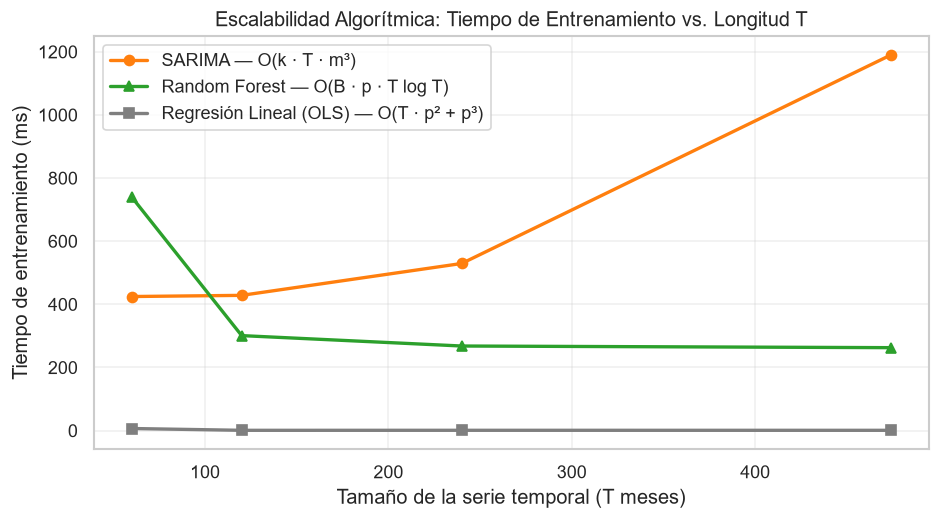

In [14]:
import time

longitudes_T = [60, 120, 240, len(y_valido)]
resultados_ml_bench = []

for T in longitudes_T:
    y_sub = y_valido[:T]
    X_ols_sub = X_ols[mask_valido][:T]
    meses_sub = df.loc[mask_valido, "mes"].values[:T]

    # 1. Tiempo Regresión Lineal Múltiple (promedio 20 corridas)
    t0 = time.perf_counter()
    for _ in range(20):
        LinearRegression().fit(X_ols_sub, y_sub)
    t_ols = (time.perf_counter() - t0) / 20.0

    # 2. Tiempo Random Forest (300 árboles)
    X_rf_sub, y_rf_sub = preparar_datos_rf(y_sub, meses_sub)
    t0 = time.perf_counter()
    RandomForestRegressor(n_estimators=300, max_depth=8, min_samples_leaf=3, random_state=42, n_jobs=-1).fit(X_rf_sub, y_rf_sub)
    t_rf = time.perf_counter() - t0

    # 3. Tiempo SARIMA
    t0 = time.perf_counter()
    SARIMAX(y_sub, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12),
            enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)
    t_sarima = time.perf_counter() - t0

    resultados_ml_bench.append({
        "Meses (T)": T,
        "OLS (ms)": round(t_ols * 1000, 3),
        "Random Forest (ms)": round(t_rf * 1000, 2),
        "SARIMA (ms)": round(t_sarima * 1000, 2)
    })

df_bench_3m = pd.DataFrame(resultados_ml_bench)
print("--- Complejidad Empírica en Entrenamiento (3 Modelos) ---")
print(df_bench_3m.to_string(index=False))

plt.figure(figsize=(8, 4.5))
plt.plot(df_bench_3m["Meses (T)"], df_bench_3m["SARIMA (ms)"], marker="o", color="#ff7f0e", linewidth=2, label="SARIMA — O(k · T · m³)")
plt.plot(df_bench_3m["Meses (T)"], df_bench_3m["Random Forest (ms)"], marker="^", color="#2ca02c", linewidth=2, label="Random Forest — O(B · p · T log T)")
plt.plot(df_bench_3m["Meses (T)"], df_bench_3m["OLS (ms)"], marker="s", color="#7f7f7f", linewidth=2, label="Regresión Lineal (OLS) — O(T · p² + p³)")
plt.title("Escalabilidad Algorítmica: Tiempo de Entrenamiento vs. Longitud T")
plt.xlabel("Tamaño de la serie temporal (T meses)")
plt.ylabel("Tiempo de entrenamiento (ms)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,Longitud_T,SARIMA_ms,Random_Forest_ms,OLS_ms
0,60,270.01,344.47,0.58
1,120,472.22,415.57,0.63
2,240,1217.86,1078.38,0.66
3,474,2645.57,1622.40,5.08


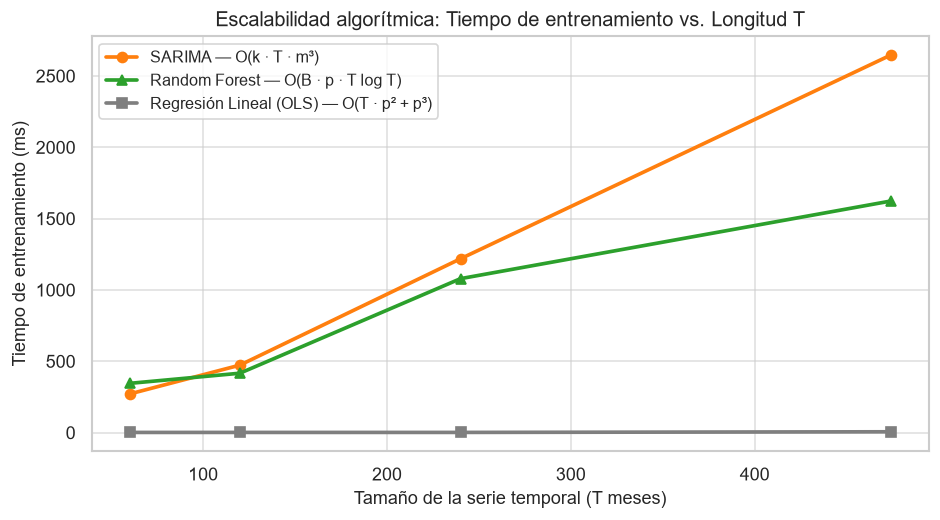

In [47]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.statespace.sarimax import SARIMAX

longitudes_T = [60, 120, 240, len(y_valido)]
resultados_ml_bench = []
X_ols_arr = np.asarray(X_ols)

# 1. Warm-up completo de los 3 modelos (evita picos de cold-start en T=60)
_ = LinearRegression().fit(X_ols_arr[mask_valido][:60], y_valido[:60])

dy_warm = np.diff(y_valido[:60])
X_rf_warm = np.array([dy_warm[i - 12:i] for i in range(12, len(dy_warm))])
_ = RandomForestRegressor(n_estimators=400, max_depth=10, random_state=42, n_jobs=1).fit(X_rf_warm, dy_warm[12:])

_ = SARIMAX(
    y_valido[:60],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False, maxiter=20)

# 2. Medición limpia de escalabilidad temporal
for T in longitudes_T:
    y_sub = y_valido[:T]
    X_ols_sub = X_ols_arr[mask_valido][:T]

    # Regresión Lineal Múltiple (OLS)
    tiempos_ols = []
    for _ in range(30):
        t0 = time.perf_counter()
        LinearRegression().fit(X_ols_sub, y_sub)
        tiempos_ols.append((time.perf_counter() - t0) * 1000)

    # Random Forest Autorregresivo (d=1, n_jobs=1 para evitar overhead de hilos)
    dy_sub = np.diff(y_sub)
    lags = 12
    X_rf_sub = np.array([dy_sub[i - lags:i] for i in range(lags, len(dy_sub))])
    y_rf_sub = dy_sub[lags:]

    tiempos_rf = []
    for _ in range(10):
        t0 = time.perf_counter()
        RandomForestRegressor(n_estimators=400, max_depth=10, random_state=42, n_jobs=1).fit(X_rf_sub, y_rf_sub)
        tiempos_rf.append((time.perf_counter() - t0) * 1000)

    # SARIMA(1,1,1)(1,1,1)12 (Filtro de Kalman + MLE)
    tiempos_sarima = []
    for _ in range(5):
        t0 = time.perf_counter()
        SARIMAX(
            y_sub,
            order=(1, 1, 1),
            seasonal_order=(1, 1, 1, 12),
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit(disp=False, maxiter=50)
        tiempos_sarima.append((time.perf_counter() - t0) * 1000)

    resultados_ml_bench.append({
        "Longitud_T": T,
        "SARIMA_ms": np.mean(tiempos_sarima),
        "Random_Forest_ms": np.mean(tiempos_rf),
        "OLS_ms": np.mean(tiempos_ols)
    })

df_ml_bench = pd.DataFrame(resultados_ml_bench)
display(df_ml_bench.round(2))

# 3. Gráfica limpia para el cartel (300 DPI)
plt.figure(figsize=(8.0, 4.5), dpi=120)
plt.plot(df_ml_bench["Longitud_T"], df_ml_bench["SARIMA_ms"], "o-", color="#ff7f0e", lw=2.2,
         label="SARIMA — O(k · T · m³)")
plt.plot(df_ml_bench["Longitud_T"], df_ml_bench["Random_Forest_ms"], "^-", color="#2ca02c", lw=2.2,
         label="Random Forest — O(B · p · T log T)")
plt.plot(df_ml_bench["Longitud_T"], df_ml_bench["OLS_ms"], "s-", color="#7f7f7f", lw=2.2,
         label="Regresión Lineal (OLS) — O(T · p² + p³)")

plt.title("Escalabilidad algorítmica: Tiempo de entrenamiento vs. Longitud T", fontsize=12)
plt.xlabel("Tamaño de la serie temporal (T meses)", fontsize=10.5)
plt.ylabel("Tiempo de entrenamiento (ms)", fontsize=10.5)
plt.grid(True, alpha=0.6)
plt.legend(loc="upper left", frameon=True, fontsize=9.5)
plt.tight_layout()
plt.savefig("graficas_eda/escalabilidad_modelos_T.png", dpi=300, bbox_inches="tight")
plt.show()

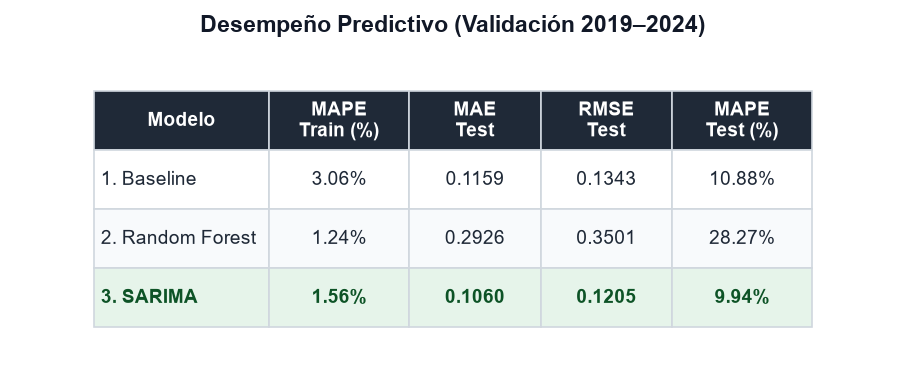

In [56]:
import os
import matplotlib.pyplot as plt

os.makedirs("graficas_eda", exist_ok=True)

# Datos con salto de línea en los nombres para reducir el ancho horizontal
datos = [
    ["1. Baseline", "3.06%", "0.1159", "0.1343", "10.88%"],
    ["2. Random Forest", "1.24%", "0.2926", "0.3501", "28.27%"],
    ["3. SARIMA", "1.56%", "0.1060", "0.1205", "9.94%"]
]

columnas = ["Modelo", "MAPE\nTrain (%)", "MAE\nTest", "RMSE\nTest", "MAPE\nTest (%)"]

# Reducción de ancho de 9.5 a 6.2 pulgadas y ajuste de altura para dos líneas por fila
fig, ax = plt.subplots(figsize=(6.2, 2.7), dpi=150)
ax.axis("off")

tabla = ax.table(
    cellText=datos,
    colLabels=columnas,
    cellLoc="center",
    loc="center",
    colWidths=[0.20, 0.16, 0.15, 0.15, 0.16]
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(9.2)
tabla.scale(1, 2.35)

for (fila, col), celda in tabla.get_celld().items():
    celda.set_edgecolor("#d0d7de")
    celda.set_linewidth(0.8)

    if fila == 0:
        celda.set_facecolor("#1f2937")
        celda.get_text().set_color("white")
        celda.get_text().set_weight("bold")
    elif fila == 3:
        celda.set_facecolor("#e6f4ea")
        celda.get_text().set_color("#0d5326")
        celda.get_text().set_weight("bold")
    else:
        celda.set_facecolor("#ffffff" if fila == 1 else "#f8fafc")
        celda.get_text().set_color("#1f2937")

    if col == 0 and fila > 0:
        celda.get_text().set_ha("left")
        celda.PAD = 0.04

plt.title(
    "Desempeño Predictivo (Validación 2019–2024)",
    fontsize=11,
    fontweight="bold",
    color="#111827",
    pad=10
)

plt.tight_layout()
plt.savefig("graficas_eda/tabla_desempeno_poster_compacta.png", dpi=300, bbox_inches="tight", transparent=False)
plt.show()

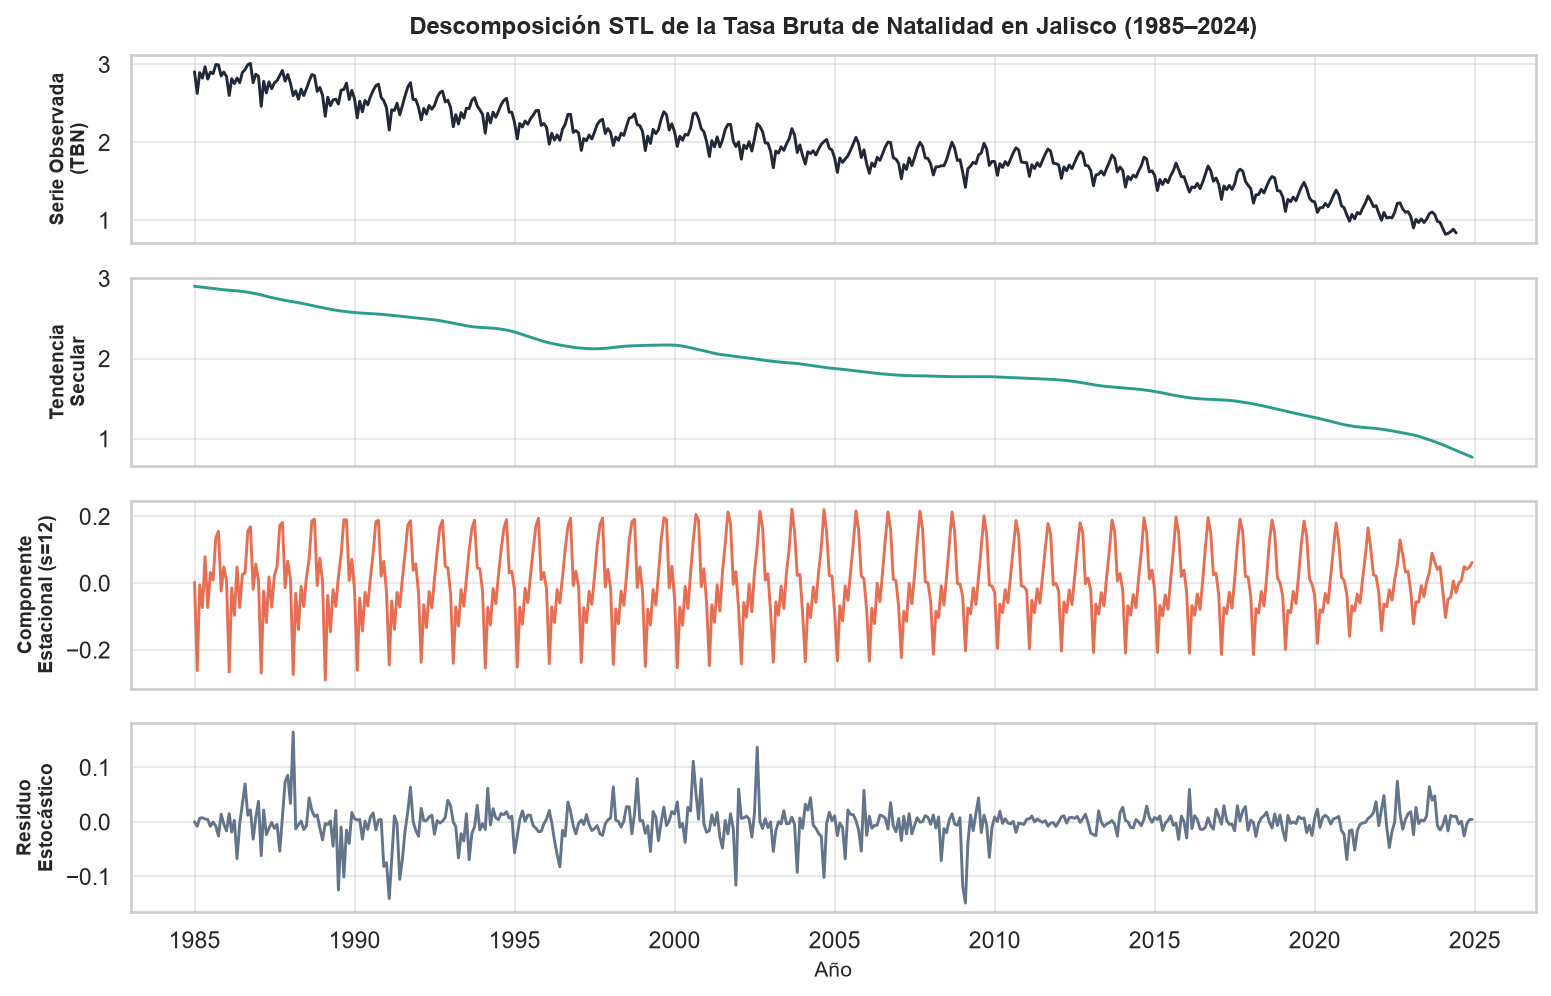

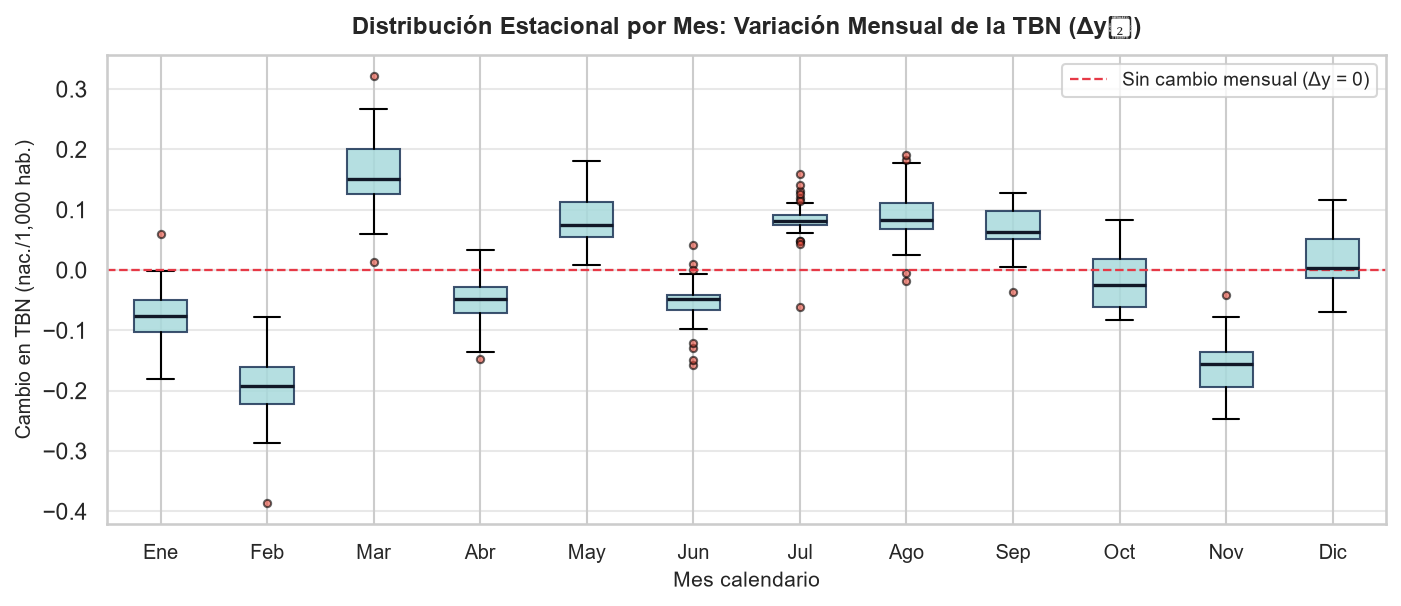

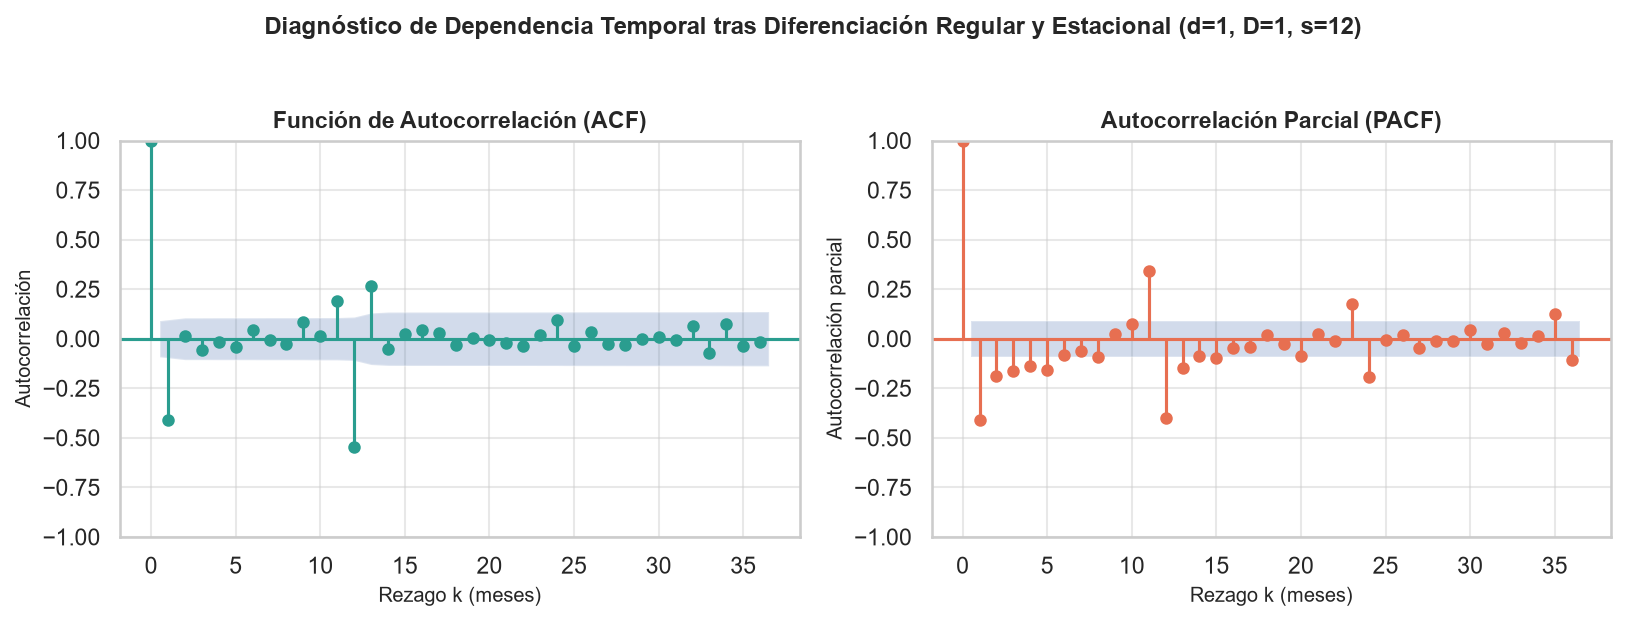

In [59]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

os.makedirs("graficas_eda", exist_ok=True)

# Preparación de la serie cronológica alineada (1985–2024) preservando los 10 meses excluidos como NaN
df_eda = df[["anio", "mes"]].copy()
df_eda["tbn"] = np.nan
df_eda.loc[mask_valido, "tbn"] = y_valido
df_eda = df_eda.sort_values(["anio", "mes"]).reset_index(drop=True)
df_eda["fecha"] = pd.to_datetime(
    df_eda["anio"].astype(str) + "-" + df_eda["mes"].astype(str).str.zfill(2) + "-01"
)
serie_tbn = df_eda.set_index("fecha")["tbn"].asfreq("MS")

# ==============================================================================
# 1. DESCOMPOSICIÓN ESTACIONAL STL (Tendencia, Estacionalidad y Residuo)
# ==============================================================================
# Interpolación temporal únicamente para continuidad visual de STL sin alterar y_valido
stl_res = STL(serie_tbn.interpolate(method="time"), period=12, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(10.5, 6.8), sharex=True, dpi=150)
componentes = [
    (serie_tbn, "Serie Observada\n(TBN)", "#1f2937"),
    (stl_res.trend, "Tendencia\nSecular", "#2a9d8f"),
    (stl_res.seasonal, "Componente\nEstacional (s=12)", "#e76f51"),
    (stl_res.resid, "Residuo\nEstocástico", "#64748b"),
]

for ax, (datos, etiqueta, color) in zip(axes, componentes):
    ax.plot(datos.index, datos.values, color=color, lw=1.4)
    ax.set_ylabel(etiqueta, fontsize=9, fontweight="bold")
    ax.grid(True, alpha=0.45)

axes[0].set_title(
    "Descomposición STL de la Tasa Bruta de Natalidad en Jalisco (1985–2024)",
    fontsize=11.5,
    fontweight="bold",
    pad=10
)
axes[-1].set_xlabel("Año", fontsize=10)

plt.tight_layout()
plt.savefig("graficas_eda/eda_descomposicion_stl.png", dpi=300, bbox_inches="tight")
plt.show()

# ==============================================================================
# 2. DIAGRAMA DE CAJA (BOXPLOT) POR MES DEL AÑO SOBRE VARIACIÓN MENSUAL (d=1)
# ==============================================================================
# .diff() sobre serie_tbn evita saltos artificiales en los meses excluidos (NaN)
dy_mensual = serie_tbn.diff().dropna()
datos_por_mes = [dy_mensual[dy_mensual.index.month == m].values for m in range(1, 13)]
nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
                 "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

fig, ax = plt.subplots(figsize=(9.5, 4.2), dpi=150)
bp = ax.boxplot(
    datos_por_mes,
    patch_artist=True,
    showfliers=True,
    flierprops=dict(marker="o", markersize=3.5, markerfacecolor="#e74c3c", alpha=0.6),
    medianprops=dict(color="#111827", linewidth=1.6)
)

for patch in bp["boxes"]:
    patch.set_facecolor("#a8dadc")
    patch.set_edgecolor("#1d3557")
    patch.set_alpha(0.85)

ax.axhline(0, color="#e63946", linestyle="--", linewidth=1.1, label="Sin cambio mensual (Δy = 0)")
ax.set_xticklabels(nombres_meses, fontsize=9.5)
ax.set_title(
    "Distribución Estacional por Mes: Variación Mensual de la TBN (Δyₜ)",
    fontsize=11.5,
    fontweight="bold",
    pad=10
)
ax.set_xlabel("Mes calendario", fontsize=10)
ax.set_ylabel("Cambio en TBN (nac./1,000 hab.)", fontsize=9.5)
ax.grid(True, axis="y", alpha=0.45)
ax.legend(loc="upper right", fontsize=9, frameon=True)

plt.tight_layout()
plt.savefig("graficas_eda/eda_boxplot_mensual.png", dpi=300, bbox_inches="tight")
plt.show()

# ==============================================================================
# 3. CORRELOGRAMAS ACF Y PACF SOBRE SERIE ESTACIONARIA (d=1, D=1, s=12)
# ==============================================================================
serie_estacionaria = serie_tbn.diff(1).diff(12).dropna()

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.0), dpi=150)

plot_acf(serie_estacionaria, lags=36, ax=axes[0], color="#2a9d8f", vlines_kwargs={"colors": "#2a9d8f"})
axes[0].set_title("Función de Autocorrelación (ACF)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Rezago k (meses)", fontsize=9.5)
axes[0].set_ylabel("Autocorrelación", fontsize=9.5)
axes[0].grid(True, alpha=0.45)

plot_pacf(serie_estacionaria, lags=36, ax=axes[1], method="ywm", color="#e76f51", vlines_kwargs={"colors": "#e76f51"})
axes[1].set_title("Autocorrelación Parcial (PACF)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Rezago k (meses)", fontsize=9.5)
axes[1].set_ylabel("Autocorrelación parcial", fontsize=9.5)
axes[1].grid(True, alpha=0.45)

plt.suptitle(
    "Diagnóstico de Dependencia Temporal tras Diferenciación Regular y Estacional (d=1, D=1, s=12)",
    fontsize=11.5,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()
plt.savefig("graficas_eda/eda_acf_pacf.png", dpi=300, bbox_inches="tight")
plt.show()

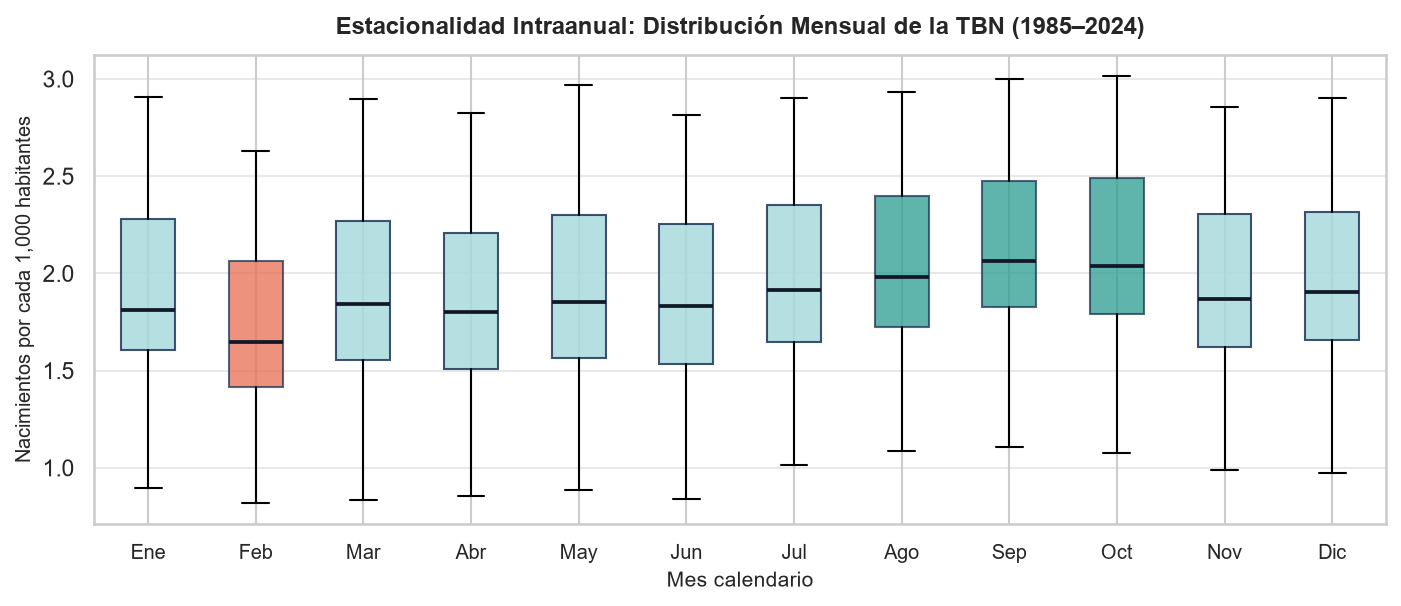

In [60]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("graficas_eda", exist_ok=True)

# Asegurar serie cronológica en niveles (1985–2024) usando df, mask_valido y y_valido
df_eda = df[["anio", "mes"]].copy()
df_eda["tbn"] = np.nan
df_eda.loc[mask_valido, "tbn"] = y_valido
df_eda = df_eda.sort_values(["anio", "mes"]).reset_index(drop=True)
df_eda["fecha"] = pd.to_datetime(
    df_eda["anio"].astype(str) + "-" + df_eda["mes"].astype(str).str.zfill(2) + "-01"
)
serie_tbn = df_eda.set_index("fecha")["tbn"].asfreq("MS")

datos_niveles = [serie_tbn[serie_tbn.index.month == m].dropna().values for m in range(1, 13)]
nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
                 "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

fig, ax = plt.subplots(figsize=(9.5, 4.2), dpi=150)
bp = ax.boxplot(
    datos_niveles,
    patch_artist=True,
    showfliers=True,
    flierprops=dict(marker="o", markersize=3.5, markerfacecolor="#e74c3c", alpha=0.6),
    medianprops=dict(color="#111827", linewidth=1.8)
)

for idx, patch in enumerate(bp["boxes"]):
    # Destacar febrero (mínimo) y agosto–octubre (máximos) con un tono ligeramente más intenso
    if idx in [7, 8, 9]:      # Ago, Sep, Oct
        patch.set_facecolor("#2a9d8f")
        patch.set_alpha(0.75)
    elif idx == 1:            # Feb
        patch.set_facecolor("#e76f51")
        patch.set_alpha(0.75)
    else:
        patch.set_facecolor("#a8dadc")
        patch.set_alpha(0.85)
    patch.set_edgecolor("#1d3557")

ax.set_xticklabels(nombres_meses, fontsize=9.5)
ax.set_title(
    "Estacionalidad Intraanual: Distribución Mensual de la TBN (1985–2024)",
    fontsize=11.5,
    fontweight="bold",
    pad=10
)
ax.set_xlabel("Mes calendario", fontsize=10)
ax.set_ylabel("Nacimientos por cada 1,000 habitantes", fontsize=9.5)
ax.grid(True, axis="y", alpha=0.45)

plt.tight_layout()
plt.savefig("graficas_eda/eda_boxplot_niveles.png", dpi=300, bbox_inches="tight")
plt.show()